# Laboratorio 2 - Modelos de Clasificación.
UPSO - Tecnicatura en Tecnologías de la Programación - 2026

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split

In [53]:
df = pd.read_csv("Canciones_Spotify.csv")

print("Cantidad de muestras o casos (filas del dataset):", df.shape[0])
print("Cantidad de características, features o columnas:", df.shape[1])
print("Cantidad de clases:", df['target'].nunique())

Cantidad de muestras o casos (filas del dataset): 2017
Cantidad de características, features o columnas: 16
Cantidad de clases: 2


1 Indica que la canción fue del agrado del usuario.

0 Indica que la canción no fue del agrado del usuario.

In [54]:
print("Cantidad de cada valor único:")
print(df['target'].value_counts()) # Cuantos valores únicos de la columna target.

Cantidad de cada valor único:
target
1    1020
0     997
Name: count, dtype: int64


In [55]:
print("Cantidad de valores vacios por columna: ",df.isnull().sum())

Cantidad de valores vacios por columna:  acousticness        0
danceability        0
duration_ms         0
energy              0
instrumentalness    0
key                 0
liveness            0
loudness            0
mode                0
speechiness         0
tempo               0
time_signature      0
valence             0
target              0
song_title          0
artist              0
dtype: int64


In [56]:
# Crear un diccionario con las traducciones
columnas_espanol = {
    'acousticness': 'acusticidad',
    'danceability': 'bailabilidad',
    'duration_ms': 'duracion_ms',
    'energy': 'energia',
    'instrumentalness': 'instrumentalidad',
    'key': 'nota_musical',
    'liveness': 'presencia_público',  # o 'en_vivo'
    'loudness': 'volumen_db',
    'mode': 'modo',
    'speechiness': 'presencia_voz',
    'tempo': 'ritmo_tempo',
    'time_signature': 'compas',
    'valence': 'positividad_valencia',
    'target': 'objetivo_gusta',
    'song_title': 'titulo_cancion',
    'artist': 'artista'
}

# Renombrar las columnas en el DataFrame original
df = df.rename(columns=columnas_espanol)

# Verificar los nuevos nombres y que no haya nulos
print("Cantidad de valores vacíos por columna (en español):")
print(df.isnull().sum())

Cantidad de valores vacíos por columna (en español):
acusticidad             0
bailabilidad            0
duracion_ms             0
energia                 0
instrumentalidad        0
nota_musical            0
presencia_público       0
volumen_db              0
modo                    0
presencia_voz           0
ritmo_tempo             0
compas                  0
positividad_valencia    0
objetivo_gusta          0
titulo_cancion          0
artista                 0
dtype: int64


## 1.1 ¿Qué columnas son útiles para la clasificación?

titulo_cancion: Cada canción suele tener un título único. 

El modelo no puede aprender una regla matemática basada en un texto que probablemente no se repita en canciones futuras.

También se podría eliminar Artista. Pero es preferible aplicar codificación ya que parece relevante para la clasificación de agrado del usuario. Antes de aplicar la codificación veremos si hay muchos artistas únicos o pocos.

In [57]:
print("Total de canciones (muestras):", len(df))
print("Artistas únicos en el dataset:", df['artista'].nunique())

Total de canciones (muestras): 2017
Artistas únicos en el dataset: 1343


Al haber tantos artistas únicos se podría eliminar la característica

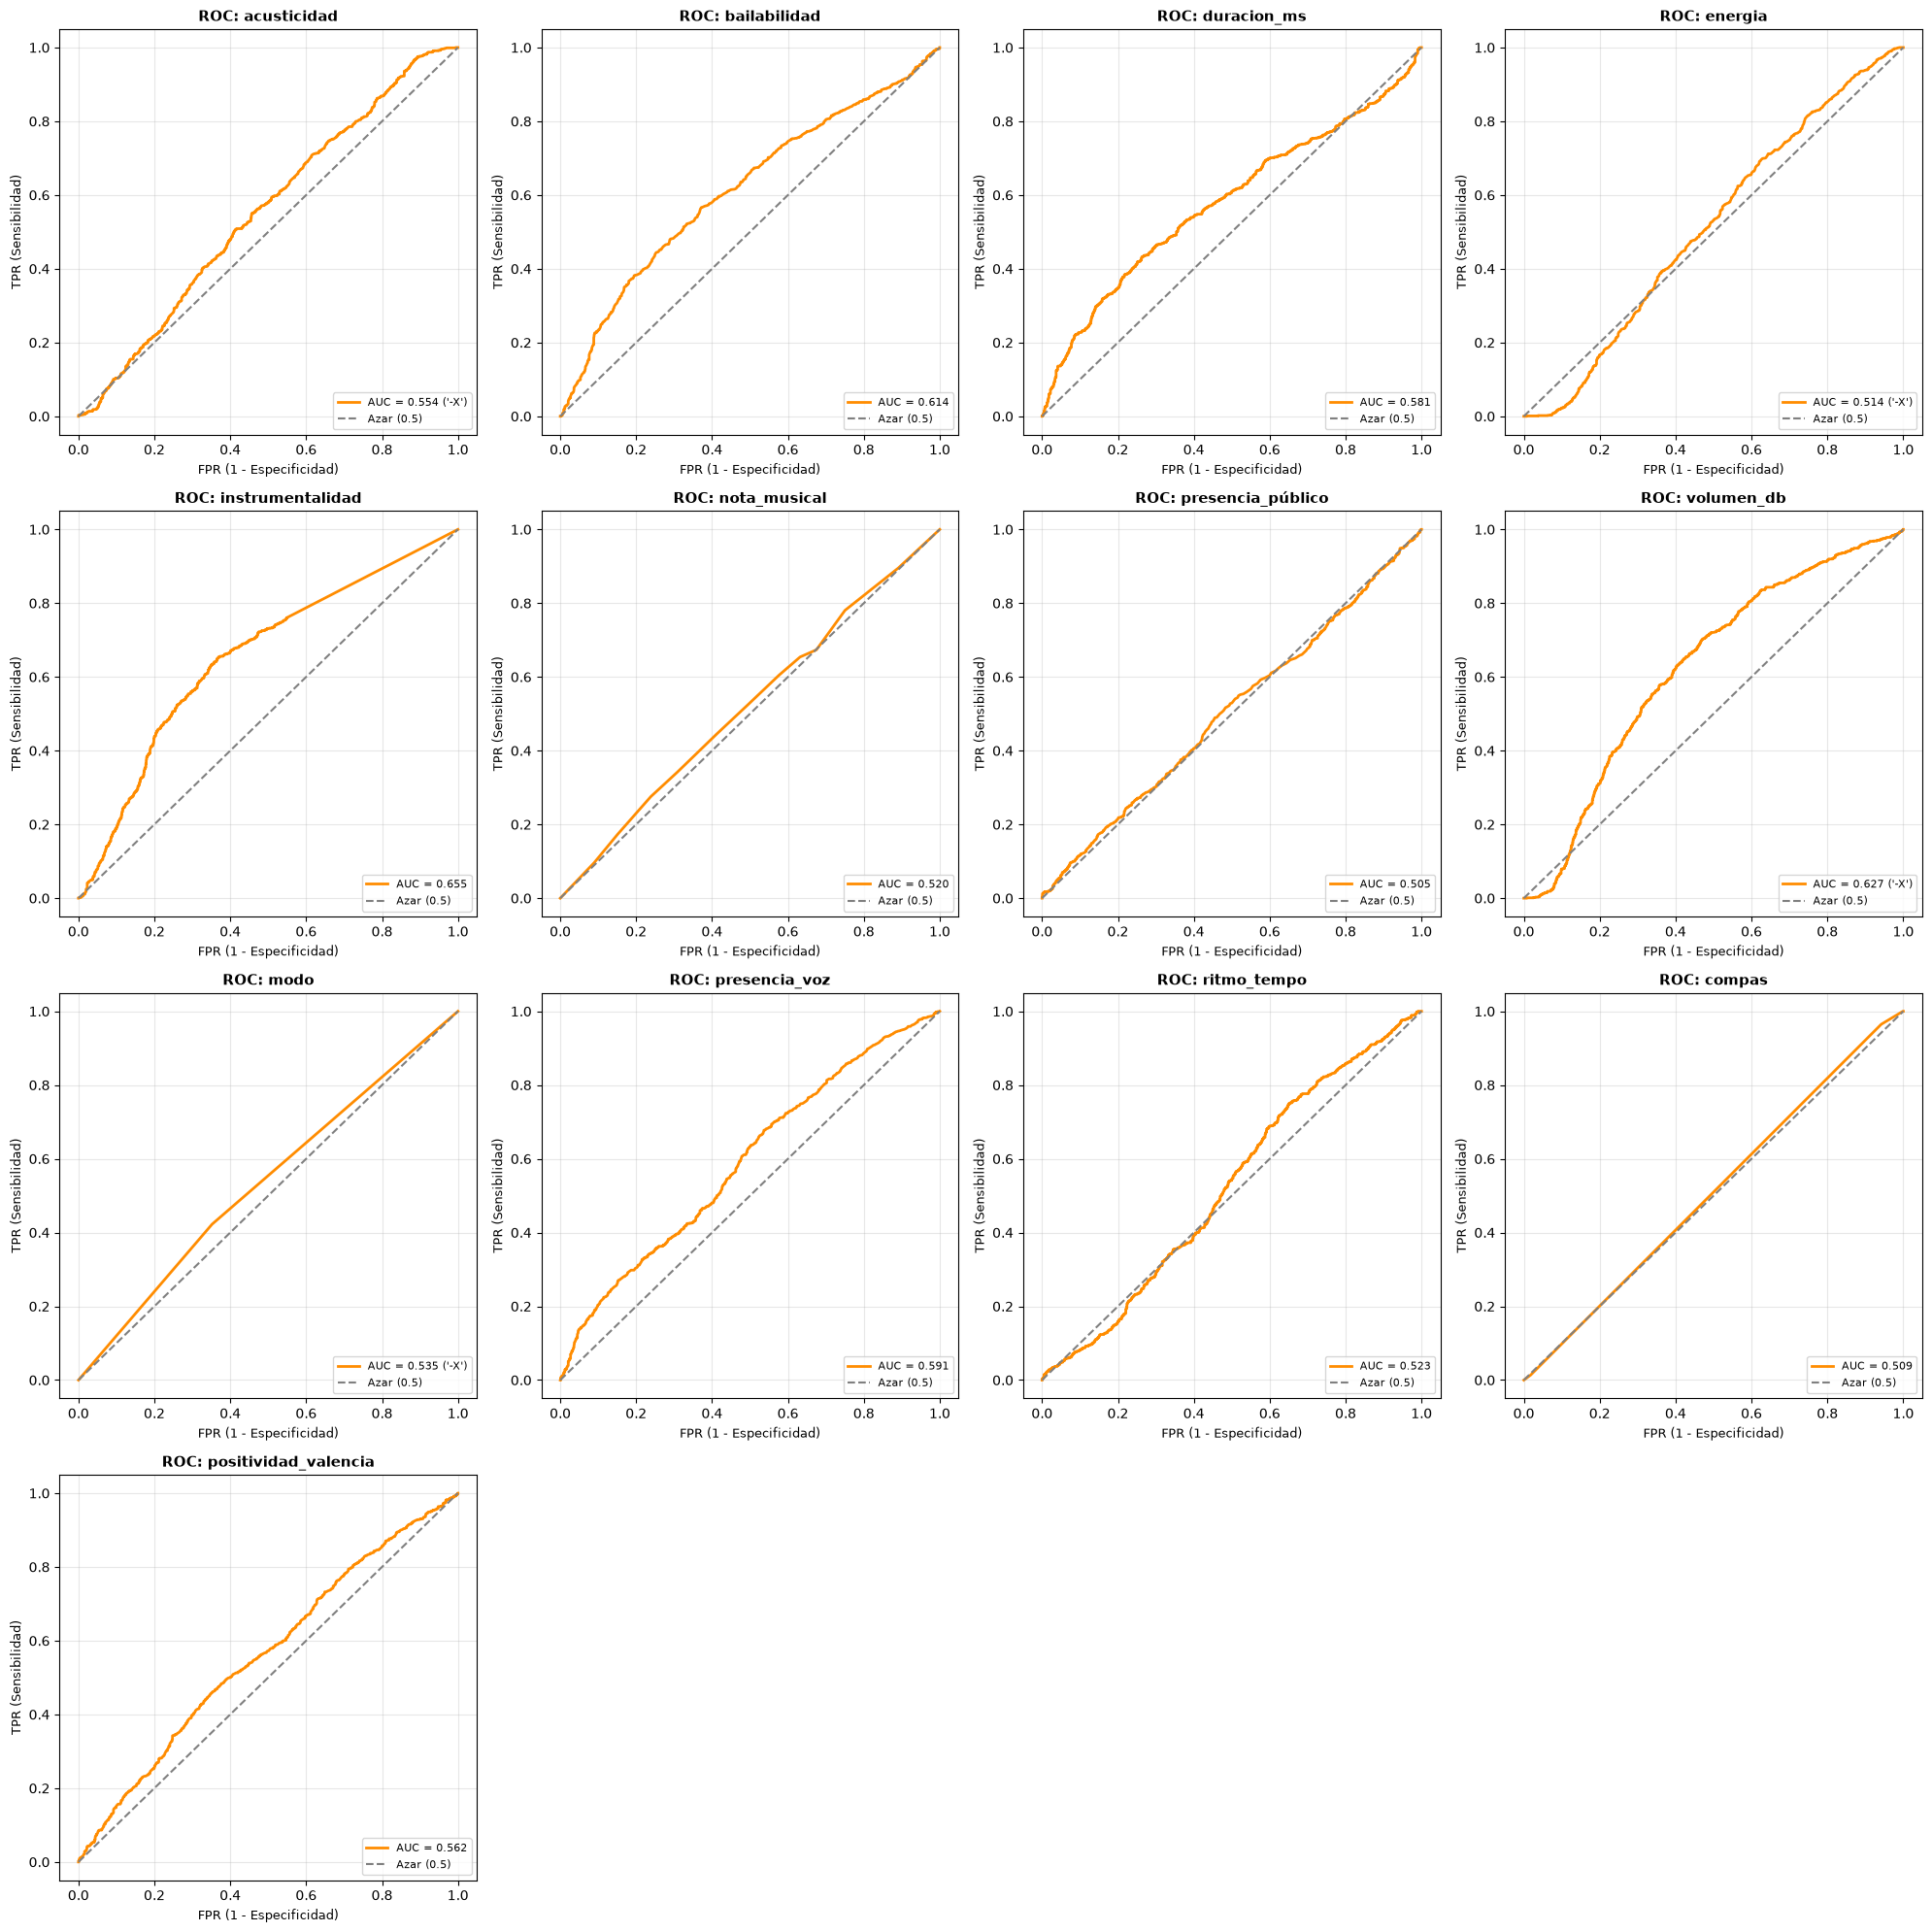

In [58]:
import math
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 1. Definir el target y separar las características numéricas
columna_target = "objetivo_gusta" 

y = df[columna_target].to_numpy()
caracteristicas_numericas = df.drop(columns=[columna_target]).select_dtypes(include=np.number).columns
total_graficos = len(caracteristicas_numericas)

# 2. Configurar la grilla de subplots dinámicamente (4 columnas)
ncols = 4
nrows = math.ceil(total_graficos / ncols)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 5 * nrows))
axes = axes.flatten()

resultados_auc = {}

# 3. Iterar y graficar asegurando el sentido correcto
for i, caracteristica in enumerate(caracteristicas_numericas):
    ax = axes[i]
    puntajes = df[caracteristica].to_numpy()

    # Filtrar posibles valores nulos
    mascara_valida = ~np.isnan(puntajes)
    y_valido = y[mascara_valida]
    puntajes_validos = puntajes[mascara_valida]

    # Curva inicial en sentido directo (+X)
    fpr, tpr, _ = roc_curve(y_valido, puntajes_validos, pos_label=1)
    area = auc(fpr, tpr)
    
    # Si AUC < 0.5, la variable tiene correlación negativa con el target:
    # Se invierten las puntuaciones (-X) para orientar la curva por encima del azar
    invertida = False
    if area < 0.5:
        fpr, tpr, _ = roc_curve(y_valido, -puntajes_validos, pos_label=1)
        area = auc(fpr, tpr)
        invertida = True

    resultados_auc[caracteristica] = {
        "AUC": round(area, 4),
        "Sentido": "Invertida (-X)" if invertida else "Directa (+X)"
    }

    etiqueta = f"AUC = {area:.3f} ('-X')" if invertida else f"AUC = {area:.3f}"
    ax.plot(fpr, tpr, label=etiqueta, color="darkorange", lw=2)
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (0.5)")
    
    ax.set_xlabel("FPR (1 - Especificidad)", fontsize=9)
    ax.set_ylabel("TPR (Sensibilidad)", fontsize=9)
    ax.set_title(f"ROC: {caracteristica}", fontsize=11, fontweight="bold")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=0.3)

# 4. Ocultar los cuadrantes sobrantes de la grilla
for j in range(total_graficos, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 1.3. Área bajo la curva (AUC) por característica

A continuación se presenta el ranking univariado de las características numéricas evaluadas, ordenadas de mayor a menor capacidad de discriminación frente a la preferencia del usuario:

| Ranking | Característica | AUC Corregido | Sentido / Relación | Capacidad Predictiva |
| :---: | :--- | :---: | :---: | :--- |
| **1** | `instrumentalidad` | 0.655 | Directa (+X) | Pobre / Moderada |
| **2** | `volumen_db` | 0.627 | Inversa (-X) | Pobre / Moderada |
| **3** | `bailabilidad` | 0.614 | Directa (+X) | Pobre / Moderada |
| **4** | `presencia_voz` | 0.591 | Directa (+X) | Débil / Casi azar |
| **5** | `duracion_ms` | 0.581 | Directa (+X) | Débil / Casi azar |
| **6** | `positividad_valencia` | 0.562 | Directa (+X) | Débil / Casi azar |
| **7** | `acusticidad` | 0.554 | Inversa (-X) | Débil / Casi azar |
| **8** | `modo` | 0.535 | Inversa (-X) | Sin discriminación |
| **9** | `ritmo_tempo` | 0.523 | Directa (+X) | Sin discriminación |
| **10** | `nota_musical` | 0.520 | Directa (+X) | Sin discriminación |
| **11** | `energia` | 0.514 | Inversa (-X) | Sin discriminación |
| **12** | `compas` | 0.509 | Directa (+X) | Sin discriminación |
| **13** | `presencia_público` | 0.505 | Directa (+X) | Azar puro |

---

#### 1.3.1. ¿Qué nos dice el AUC sobre la capacidad de cada característica para predecir las preferencias del usuario?

El valor de **ROC-AUC** cuantifica la probabilidad de que, al tomar al azar una canción que le gusta al usuario ($y=1$) y otra que no le gusta ($y=0$), la característica evaluada asigne una puntuación mayor a la canción preferida. A partir de los resultados obtenidos se concluye lo siguiente:

1. **Ausencia de predictores univariados fuertes:** Ninguna variable acústica alcanza un AUC superior a $0.70$. La característica con mayor capacidad explicativa es `instrumentalidad` (0.655), lo que demuestra que las preferencias musicales no dependen de una sola dimensión lineal aislada, requiriendo modelos multivariados que capturen interacciones no lineales.
2. **Grupo con señal predictiva útil:** Variables como `instrumentalidad` (0.655) y `bailabilidad` (0.614) exhiben una relación directa con el target (a mayor valor, mayor probabilidad de agrado). En contraposición, `volumen_db` (0.627) y `acusticidad` (0.554) muestran una relación monótona decreciente (relación inversa), requiriendo la inversión del signo para alinear la curva por encima de la diagonal.
3. **Predominio de variables sin capacidad discriminativa (ruido):** Características como `presencia_público` (0.505), `compas` (0.509), `energia` (0.514) y `ritmo_tempo` (0.523) presentan curvas prácticamente superpuestas sobre la recta de referencia diagonal ($0.5$). De forma aislada, estas variables son equivalentes a una elección aleatoria y constituyen candidatas directas a ser descartadas en la fase de selección de variables (*feature selection*).

¿Qué representa cada una en este contexto?

Sensibilidad (TPR - Tasa de Verdaderos Positivos):

Definición: De todas las canciones que existen en la plataforma y que te gustarían, ¿qué porcentaje logra recomendarte el modelo?

Error asociado: Falso Negativo (una canción buenísima para vos que el modelo no te mostró y quedó perdida en el catálogo).

Especificidad (TNR - Tasa de Verdaderos Negativos) / $1 - \text{FPR}$:

Definición: De todas las canciones que odias o no te gustan, ¿qué porcentaje logra descartar el modelo para no ponerlas en tu reproducción?

Error asociado: Falso Positivo (una canción horrible o fuera de tono que el modelo te pone a sonar en el medio de la playlist).

En la gran mayoría de las plataformas prima la especificidad por sobre la sensibilidad

Verdadero positivo (VP): el caso es positivo y el modelo lo clasificó como positivo. Acierto.

Verdadero negativo (VN): el caso es negativo y el modelo lo clasificó como negativo. Acierto.

Falso positivo (FP): el caso es negativo pero el modelo lo clasificó como positivo.

Falso negativo (FN): el caso es positivo pero el modelo lo clasificó como negativo.

In [59]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve, auc

columna_target = "objetivo_gusta"
y = df[columna_target].to_numpy()
caracteristicas_numericas = df.drop(columns=[columna_target]).select_dtypes(include=np.number).columns

metricas_atributos = []

for caracteristica in caracteristicas_numericas:
    puntajes = df[caracteristica].to_numpy()
    
    # Filtrar posibles valores nulos
    mascara_valida = ~np.isnan(puntajes)
    y_val = y[mascara_valida]
    p_val = puntajes[mascara_valida]
    
    # Curva ROC inicial
    fpr, tpr, umbrales = roc_curve(y_val, p_val, pos_label=1)
    area = auc(fpr, tpr)
    
    signo = 1
    # Orientar la variable si presenta relación inversa
    if area < 0.5:
        signo = -1
        fpr, tpr, umbrales = roc_curve(y_val, -p_val, pos_label=1)
        area = auc(fpr, tpr)
    
    # Encontrar el umbral óptimo según el Índice de Youden (J = TPR - FPR)
    indice_optimo = np.argmax(tpr - fpr)
    umbral_optimo = umbrales[indice_optimo]
    
    # Generar predicción binarizada según el umbral óptimo y signo
    y_pred = (signo * p_val >= umbral_optimo).astype(int)
    
    # Matriz de confusión: tn, fp, fn, tp
    vn, fp, fn, vp = confusion_matrix(y_val, y_pred, labels=[0, 1]).ravel()
    
    # Cálculo de métricas
    sensibilidad = vp / (vp + fn) if (vp + fn) > 0 else 0.0
    especificidad = vn / (vn + fp) if (vn + fp) > 0 else 0.0
    balanced_acc = (sensibilidad + especificidad) / 2.0
    
    metricas_atributos.append({
        "Caracteristica": caracteristica,
        "Sentido": "Inversa (-X)" if signo == -1 else "Directa (+X)",
        "VP": vp,
        "VN": vn,
        "FP": fp,
        "FN": fn,
        "Sensibilidad (TPR)": round(sensibilidad, 3),
        "Especificidad (TNR)": round(especificidad, 3),
        "Balanced Accuracy": round(balanced_acc, 3)
    })

# Crear DataFrame ordenado por Balanced Accuracy
df_metricas = (
    pd.DataFrame(metricas_atributos)
    .sort_values(by="VN", ascending=False)
    .reset_index(drop=True)
)
df_metricas.index = df_metricas.index + 1
df_metricas.index.name = "Ranking"

print(df_metricas.to_string())

               Caracteristica       Sentido   VP   VN   FP   FN  Sensibilidad (TPR)  Especificidad (TNR)  Balanced Accuracy
Ranking                                                                                                                    
1                nota_musical  Directa (+X)  281  759  238  739               0.275                0.761              0.518
2                 duracion_ms  Directa (+X)  441  735  262  579               0.432                0.737              0.585
3        positividad_valencia  Directa (+X)  465  650  347  555               0.456                0.652              0.554
4                        modo  Inversa (-X)  431  646  351  589               0.423                0.648              0.535
5            instrumentalidad  Directa (+X)  664  632  365  356               0.651                0.634              0.642
6                bailabilidad  Directa (+X)  578  626  371  442               0.567                0.628              0.597
7       

Teniendo en cuenta que lo ideal es que el modelo recomiende canciones que le agradan al usuario y descarte las que no. Se podría evaluar por Balance_accuraccy que es el promedio simple entre la sensibilidad y la especificidad, resume en un único número el rendimiento de la variable operando en su umbral de corte óptimo (Indice de Youden).

In [60]:
import numpy as np
import pandas as pd
from scipy import stats

columna_target = "objetivo_gusta"
caracteristicas_numericas = df.drop(columns=[columna_target]).select_dtypes(include=np.number).columns

grupo_gusta = df[df[columna_target] == 1]
grupo_no_gusta = df[df[columna_target] == 0]

scores_k_medios = []
scores_k_std = []

resultados_ttest = []

for col in caracteristicas_numericas:
    # Extraer valores ignorando posibles nulos
    valores_gusta = grupo_gusta[col].dropna().to_numpy()
    valores_no_gusta = grupo_no_gusta[col].dropna().to_numpy()
    
    # Prueba t de Student para muestras independientes (Welch t-test)
    t_stat, p_valor = stats.ttest_ind(valores_gusta, valores_no_gusta, equal_var=False)
    
    media_gusta = valores_gusta.mean()
    media_no_gusta = valores_no_gusta.mean()
    diferencia_medias = media_gusta - media_no_gusta
    
    # Interpretación estadística con nivel de significancia alfa = 0.05
    es_significativa = p_valor < 0.05
    
    resultados_ttest.append({
        "Caracteristica": col,
        "Media Gusta (1)": round(media_gusta, 3),
        "Media No Gusta (0)": round(media_no_gusta, 3),
        "Diferencia": round(diferencia_medias, 3),
        "Estadístico t": round(t_stat, 3),
        "p-valor": f"{p_valor:.4e}" if p_valor < 0.0001 else f"{p_valor:.4f}",
        "Diferencia Significativa (p < 0.05)": "Sí" if es_significativa else "No"
    })

# Ordenar por el p-valor más bajo (mayor significancia estadística)
df_ttest = (
    pd.DataFrame(resultados_ttest)
    .sort_values(by="Estadístico t", key=abs, ascending=False)
    .reset_index(drop=True)
)
df_ttest.index = df_ttest.index + 1
df_ttest.index.name = "Ranking"

print(df_ttest.to_string())

               Caracteristica  Media Gusta (1)  Media No Gusta (0)  Diferencia  Estadístico t     p-valor Diferencia Significativa (p < 0.05)
Ranking                                                                                                                                      
1                bailabilidad            0.647               0.590       0.057          8.064  1.2509e-15                                  Sí
2               presencia_voz            0.106               0.079       0.028          7.021  3.0796e-12                                  Sí
3            instrumentalidad            0.174               0.091       0.083          6.948  5.0305e-12                                  Sí
4                 duracion_ms       258197.575          234140.495   24057.079          6.680  3.1230e-11                                  Sí
5                 acusticidad            0.154               0.222      -0.067         -5.849  5.8249e-09                                  Sí
6     

### 1.5. Prueba de Hipótesis: T-test de Student para muestras independientes

Para contrastar formalmente si existen diferencias significativas en las medias de cada atributo entre las canciones que gustaron ($y=1$) y las que no ($y=0$), se planteó el siguiente contraste de hipótesis para cada variable:

* **Hipótesis nula ($H_0$):** $\mu_{\text{gusta}} = \mu_{\text{no gusta}}$ (No existe diferencia en la media de la característica entre ambos grupos).
* **Hipótesis alternativa ($H_1$):** $\mu_{\text{gusta}} \neq \mu_{\text{no gusta}}$ (Existe una diferencia estadísticamente significativa entre las medias).

Se utilizó la prueba **t de Welch** (`equal_var=False`).

---

#### Interpretación de las métricas obtenidas

1. **Magnitud y Signo del Estadístico $t$:**
   * **$t > 0$:** La media del grupo al que le gusta la canción es superior a la del grupo al que no le gusta (ej. `instrumentalidad`, `bailabilidad`). Confirma una relación directa con el agrado.
   * **$t < 0$:** La media es inferior en las canciones preferidas (ej. `volumen_db`, `acusticidad`). Coincide con la orientación inversa observada en las curvas ROC.
2. **Criterio de decisión con el $p$-valor ($\alpha = 0.05$):**
   * **$p < 0.05$:** Se rechaza la hipótesis nula ($H_0$). La diferencia observada entre ambos grupos no es explicable por azar muestral, evidenciando que el atributo aporta señal discriminativa real.
   * **$p \ge 0.05$:** No se rechaza $H_0$. Las características (como `presencia_público` o `compas`) presentan distribuciones con medias indistinguibles entre los agrados y desagrados, lo que respalda su eliminación en la etapa de selección de características (*Feature Selection*).


In [61]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import confusion_matrix, roc_curve, auc

columna_target = "objetivo_gusta"
y = df[columna_target].to_numpy()
caracteristicas_numericas = df.drop(columns=[columna_target]).select_dtypes(include=np.number).columns

grupo_gusta = df[df[columna_target] == 1]
grupo_no_gusta = df[df[columna_target] == 0]

resumen_atributos = []

for col in caracteristicas_numericas:
    puntajes = df[col].to_numpy()
    
    # Filtrar posibles nulos
    mascara_valida = ~np.isnan(puntajes)
    y_val = y[mascara_valida]
    p_val = puntajes[mascara_valida]
    
    # 1. Curva ROC y AUC con corrección de signo
    fpr, tpr, umbrales = roc_curve(y_val, p_val, pos_label=1)
    area = auc(fpr, tpr)
    signo = 1
    
    if area < 0.5:
        signo = -1
        fpr, tpr, umbrales = roc_curve(y_val, -p_val, pos_label=1)
        area = auc(fpr, tpr)
        
    # 2. Balanced Accuracy en el umbral óptimo (Youden)
    indice_optimo = np.argmax(tpr - fpr)
    umbral_optimo = umbrales[indice_optimo]
    y_pred = (signo * p_val >= umbral_optimo).astype(int)
    
    vn, fp, fn, vp = confusion_matrix(y_val, y_pred, labels=[0, 1]).ravel()
    sensibilidad = vp / (vp + fn) if (vp + fn) > 0 else 0.0
    especificidad = vn / (vn + fp) if (vn + fp) > 0 else 0.0
    bal_acc = (sensibilidad + especificidad) / 2.0
    
    # 3. T-test de Welch (p-valor)
    vals_1 = grupo_gusta[col].dropna().to_numpy()
    vals_0 = grupo_no_gusta[col].dropna().to_numpy()
    _, p_val_ttest = stats.ttest_ind(vals_1, vals_0, equal_var=False)
    
    resumen_atributos.append({
        "Caracteristica": col,
        "Sentido": "Inversa (-X)" if signo == -1 else "Directa (+X)",
        "AUC": round(area, 4),
        "Balanced Accuracy": round(bal_acc, 4),
        "p-value": f"{p_val_ttest:.4e}" if p_val_ttest < 0.0001 else f"{p_val_ttest:.4f}",
        "Significativo (p < 0.05)": "Sí" if p_val_ttest < 0.05 else "No"
    })

# Armar y ordenar DataFrame por AUC descendente
df_resumen = (
    pd.DataFrame(resumen_atributos)
    .sort_values(by="AUC", ascending=False)
    .reset_index(drop=True)
)
df_resumen.index = df_resumen.index + 1
df_resumen.index.name = "Ranking"

print(df_resumen.to_string())

               Caracteristica       Sentido     AUC  Balanced Accuracy     p-value Significativo (p < 0.05)
Ranking                                                                                                    
1            instrumentalidad  Directa (+X)  0.6547             0.6424  5.0305e-12                       Sí
2                  volumen_db  Inversa (-X)  0.6269             0.6163      0.0013                       Sí
3                bailabilidad  Directa (+X)  0.6144             0.5973  1.2509e-15                       Sí
4               presencia_voz  Directa (+X)  0.5907             0.5704  3.0796e-12                       Sí
5                 duracion_ms  Directa (+X)  0.5807             0.5848  3.1230e-11                       Sí
6        positividad_valencia  Directa (+X)  0.5624             0.5539  1.1793e-06                       Sí
7                 acusticidad  Inversa (-X)  0.5535             0.5468  5.8249e-09                       Sí
8                        mod

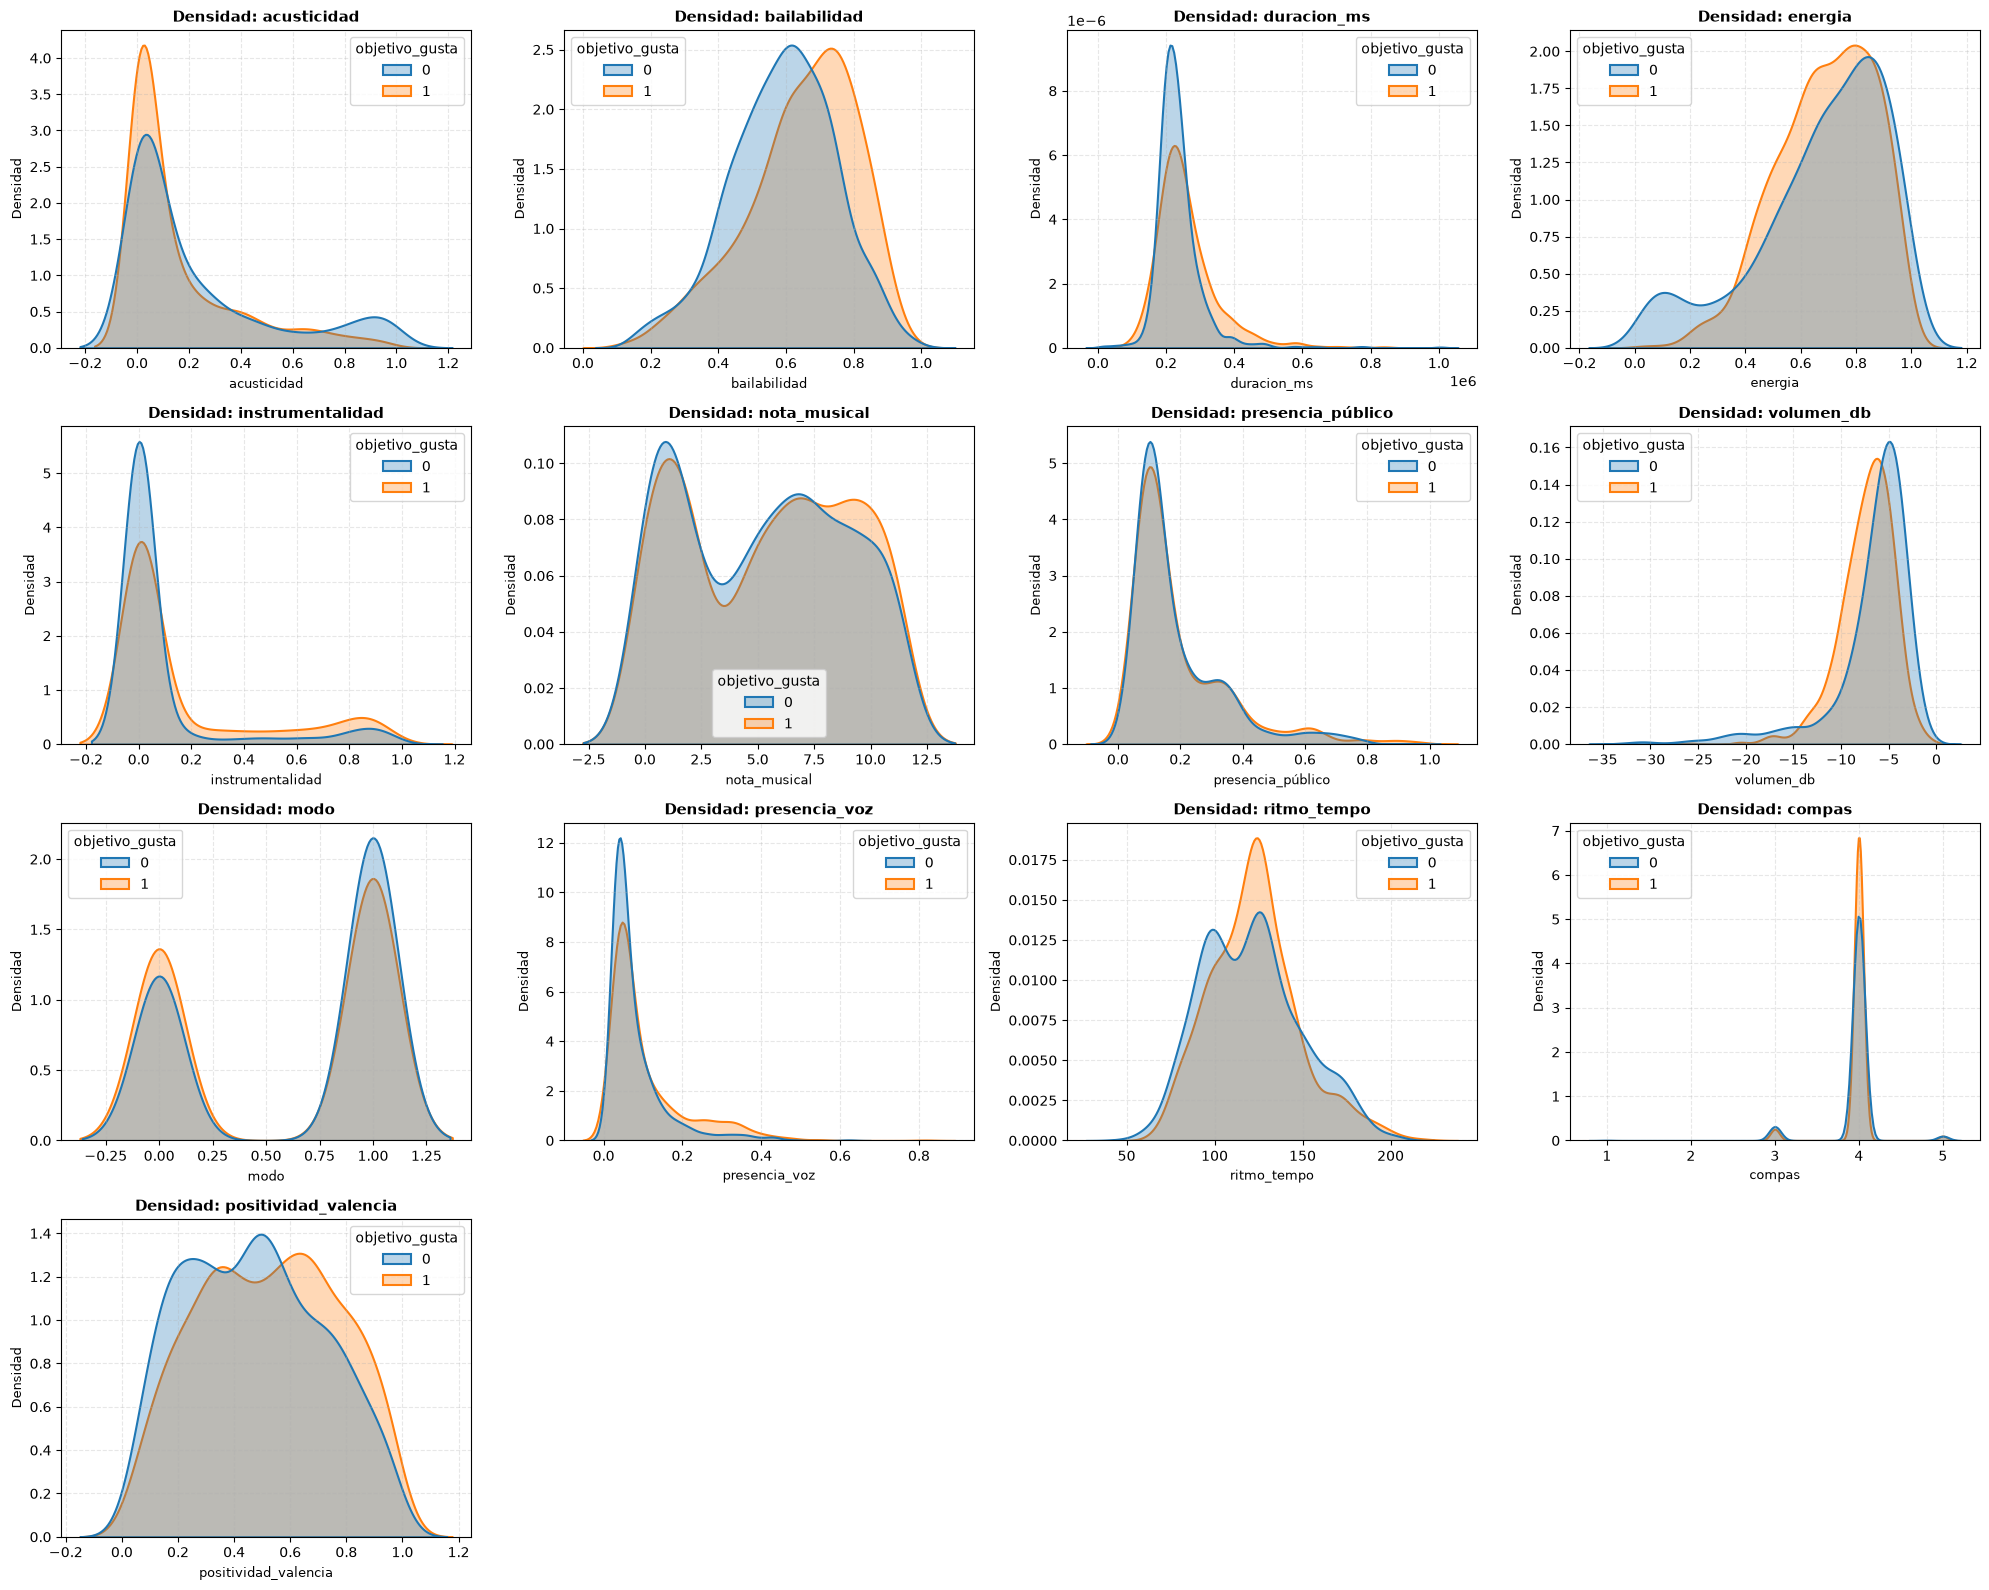

In [62]:
import seaborn as sns
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(caracteristicas_numericas):
    ax = axes[i]
    
    sns.kdeplot(
        data=df,
        x=col,
        hue=columna_target,
        common_norm=False,
        fill=True,
        alpha=0.3,
        linewidth=1.5,
        ax=ax
    )
    
    ax.set_title(f"Densidad: {col}", fontsize=11, fontweight="bold")
    ax.set_xlabel(col, fontsize=9)
    ax.set_ylabel("Densidad", fontsize=9)
    ax.grid(linestyle="--", alpha=0.3)

for j in range(total_graficos, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 1.8. ¿Las características con mayor AUC son la mejor combinación para entrenar el modelo?

**Respuesta: No necesariamente.** 

Aunque el cálculo univariado del AUC es útil como una primera aproximación exploratoria para identificar variables prometedoras y descartar ruido estadístico evidente, quedarse simplemente con el subconjunto de mayor AUC presenta desventajas críticas.

Las desventajas son:

* **Redundancia entre variables:** el AUC se calcula de a una variable por vez. Dos atributos con AUC alto pueden estar muy correlacionados entre sí (por ejemplo, `volumen_db` y `energia` o `acusticidad`) y aportar casi la misma información, por lo que sumar ambos no mejora el modelo.
* **Interacciones:** una variable con AUC cercano a 0.5 por sí sola puede ser útil en combinación con otras. El AUC univariado no detecta esas interacciones, que modelos como KNN o los árboles sí aprovechan.
* **Depende del modelo:** la mejor combinación de atributos depende del algoritmo que se use. Por eso conviene validarla con el propio modelo (validación cruzada o técnicas de *feature selection*, como se hace en la sección 5).

En conclusión, el AUC sirve como filtro inicial para descartar variables que se comportan como el azar, pero la combinación final debe elegirse evaluando el rendimiento del modelo con validación cruzada.


### Síntesis del Análisis Univariado de Atributos

1. **Predictores dominantes:**
   * Las tres variables acústicas con mayor capacidad discriminativa son `instrumentalidad` ($\text{AUC} = 0.655$), `volumen_db` ($\text{AUC} = 0.627$) y `bailabilidad` ($\text{AUC} = 0.614$). Todas presentan $p\text{-valores} < 0.005$, confirmando diferencias significativas en sus medias frente al agrado del oyente.
   * La relación es **directa** para `instrumentalidad` y `bailabilidad` (el usuario prefiere temas más bailables e instrumentales) e **inversa** para `volumen_db` (prefiere temas con menor volumen relativo/compresión).

2. **Variables de soporte estadístico secundario:**
   * `presencia_voz`, `duracion_ms`, `positividad_valencia` y `acusticidad` exhiben un poder univariado bajo ($0.55 \le \text{AUC} < 0.60$), pero con alta significancia estadística ($p < 0.05$).

3. **Variables ruidosas a descartar en Feature Selection:**
   * `presencia_público`, `compas`, `energia`, `nota_musical` y `ritmo_tempo` presentan $p \ge 0.05$, $\text{AUC} \approx 0.50$ y superposición casi absoluta en sus curvas de densidad. No aportan capacidad predictiva individual y son candidatas a remoción previa para evitar sobreajuste y multicolinealidad.

In [63]:
X = df.drop(columns=['objetivo_gusta','titulo_cancion', 'artista']) 
y = df[columna_target]

# Columnas numéricas que escala el StandardScaler dentro de los pipelines (sección 3)
cols_numericas = X.columns.tolist()

X.columns

Index(['acusticidad', 'bailabilidad', 'duracion_ms', 'energia',
       'instrumentalidad', 'nota_musical', 'presencia_público', 'volumen_db',
       'modo', 'presencia_voz', 'ritmo_tempo', 'compas',
       'positividad_valencia'],
      dtype='str')

## 2. Separación de datos de entrenamiento y prueba

### 2.1 train_test_split

Se separa un 20% de los datos para test. Se usa `stratify=y` para que ambas particiones mantengan la misma proporción de canciones que gustan y que no, y `random_state=42` para que el resultado sea reproducible.


In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

# 3. Comprobar que ambas particiones quedaron perfectamente balanceadas
print(f"Muestras de entrenamiento (X_train): {X_train.shape[0]}")
print(f"Muestras de prueba (X_test): {X_test.shape[0]}\n")
print(f"Muestras de entrenamiento (y_train): {y_train.shape[0]}")
print(f"Muestras de prueba (y_test): {y_test.shape[0]}\n")

print("Distribución de clases en Entrenamiento:")
print(y_train.value_counts(normalize=True).round(4) * 100)

print("\nDistribución de clases en Prueba:")
print(y_test.value_counts(normalize=True).round(4) * 100)

Muestras de entrenamiento (X_train): 1613
Muestras de prueba (X_test): 404

Muestras de entrenamiento (y_train): 1613
Muestras de prueba (y_test): 404

Distribución de clases en Entrenamiento:
objetivo_gusta
1    50.59
0    49.41
Name: proportion, dtype: float64

Distribución de clases en Prueba:
objetivo_gusta
1    50.5
0    49.5
Name: proportion, dtype: float64


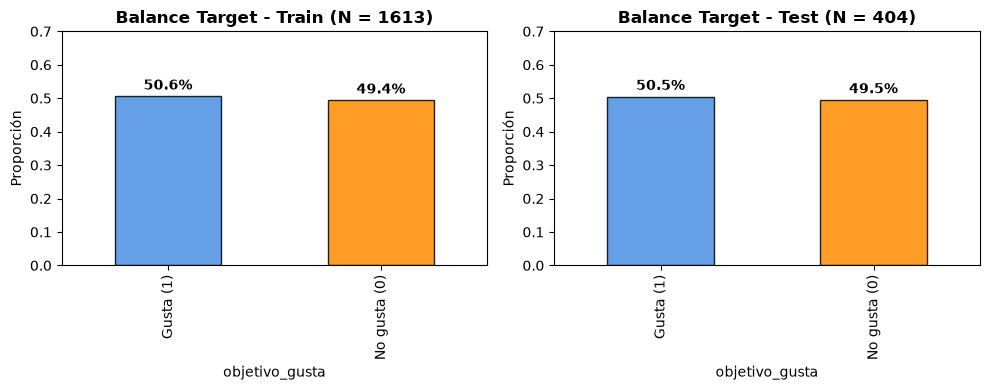

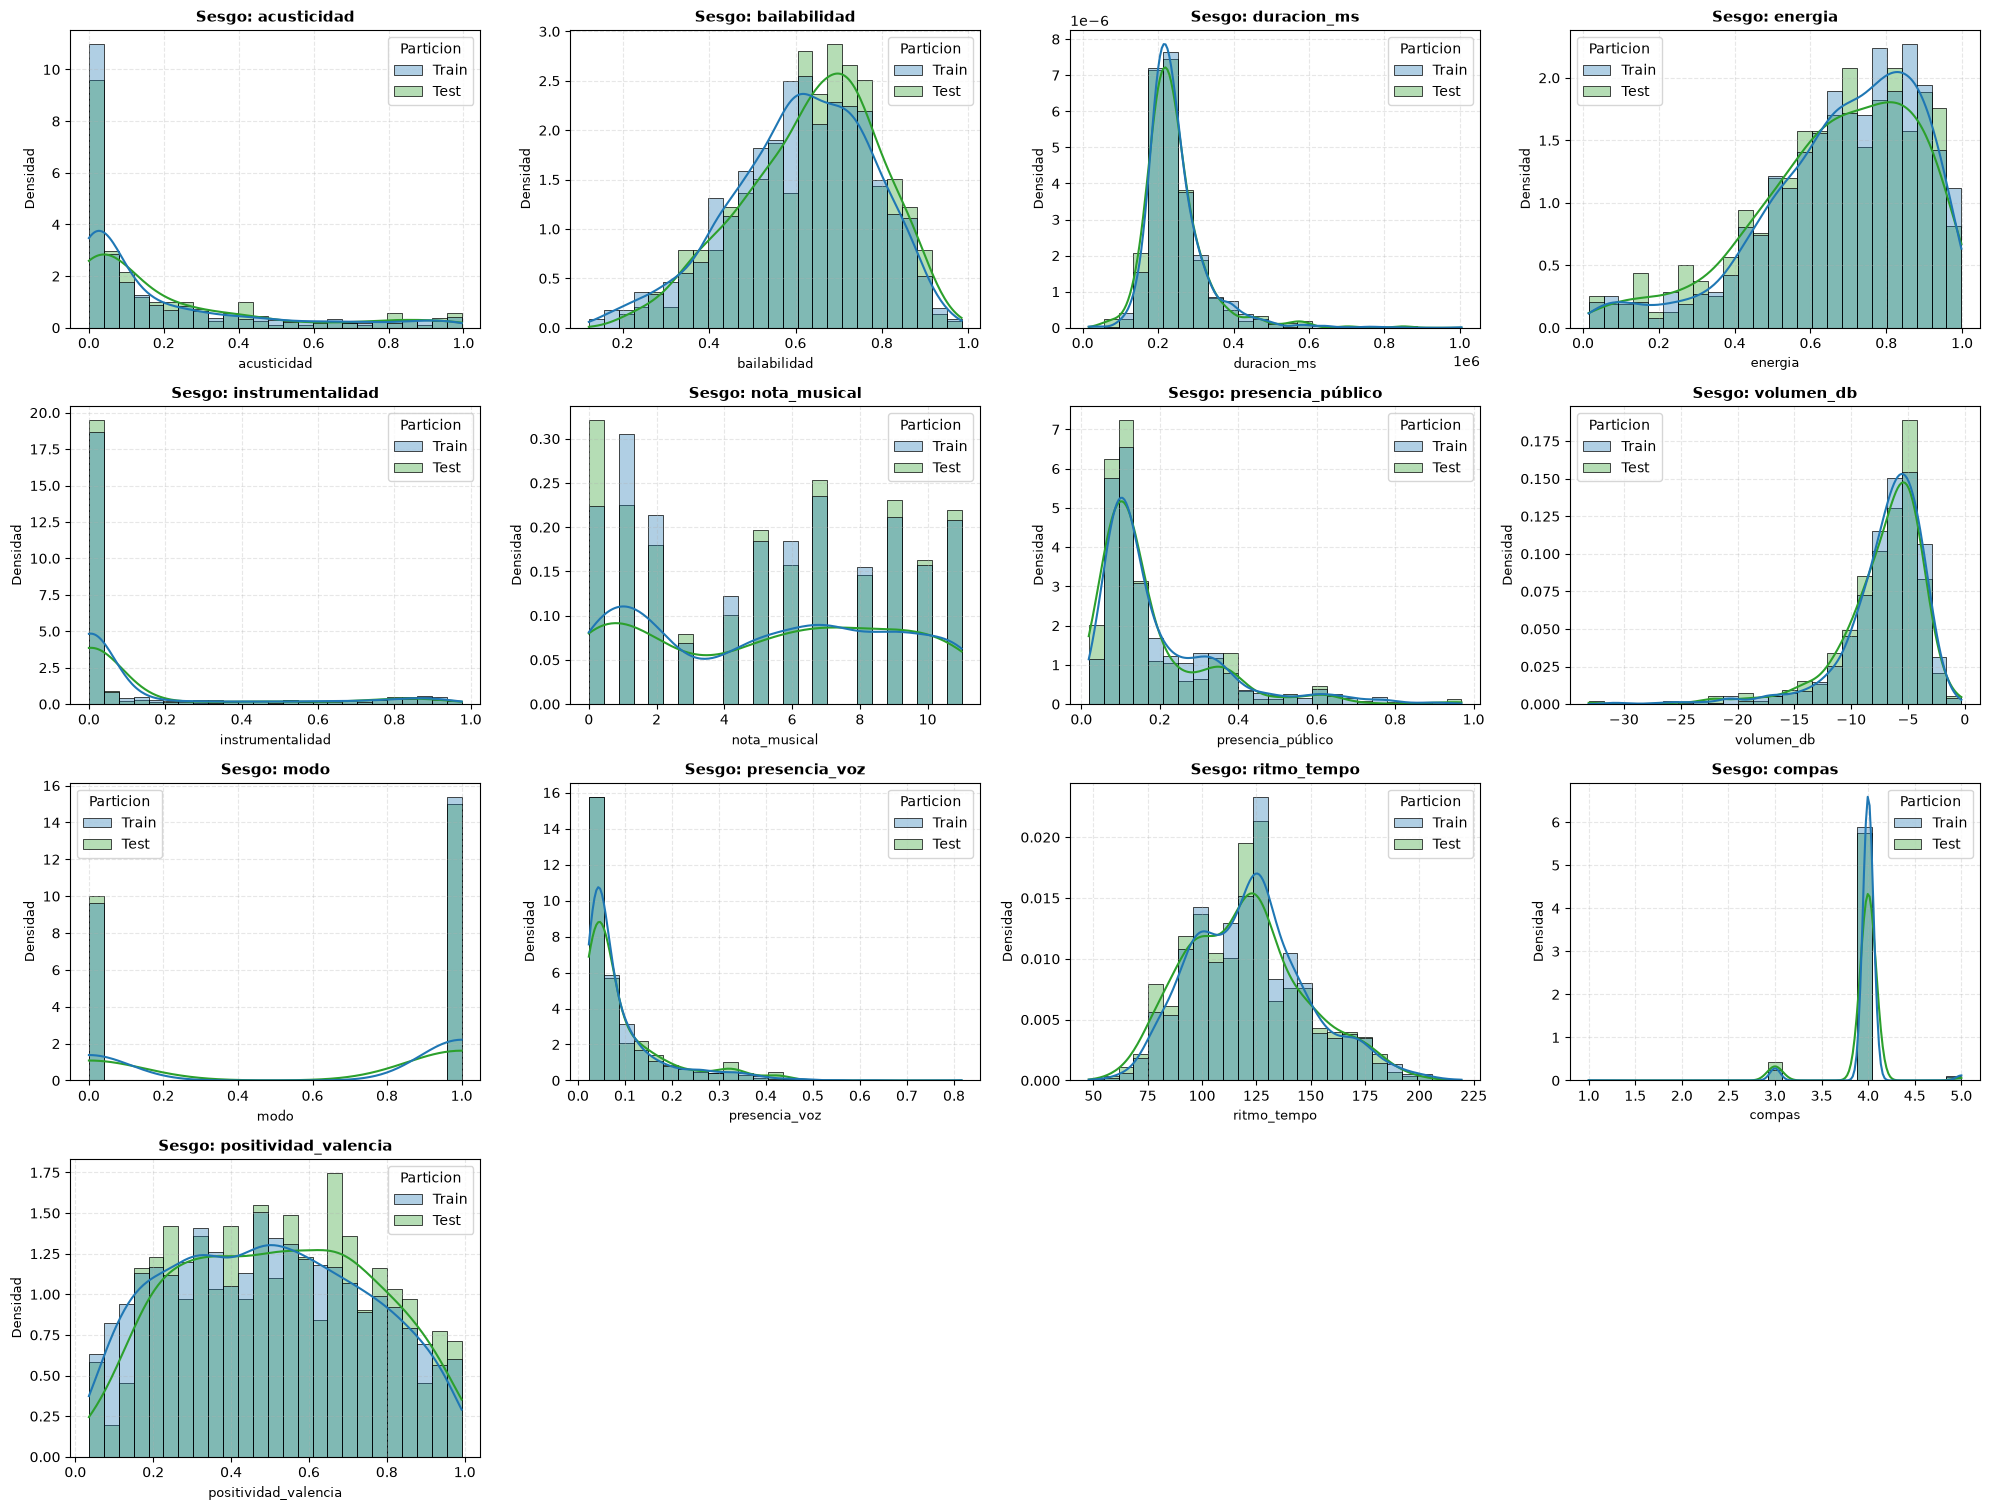

In [66]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================
# 1. ANÁLISIS DEL BALANCE DEL TARGET
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colores_target = ["#4A90E2", "#FF8C00"] # 0: No gusta, 1: Gusta

# Proporciones en train y test
df_train_balance = y_train.value_counts(normalize=True).rename({0: "No gusta (0)", 1: "Gusta (1)"})
df_test_balance = y_test.value_counts(normalize=True).rename({0: "No gusta (0)", 1: "Gusta (1)"})

df_train_balance.plot(kind="bar", ax=axes[0], color=colores_target, edgecolor="black", alpha=0.85)
axes[0].set_title(f"Balance Target - Train (N = {len(y_train)})", fontweight="bold")
axes[0].set_ylabel("Proporción")
axes[0].set_ylim(0, 0.7)

for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.02), ha="center", fontsize=10, fontweight="bold")

df_test_balance.plot(kind="bar", ax=axes[1], color=colores_target, edgecolor="black", alpha=0.85)
axes[1].set_title(f"Balance Target - Test (N = {len(y_test)})", fontweight="bold")
axes[1].set_ylabel("Proporción")
axes[1].set_ylim(0, 0.7)

for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.02), ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

# ==============================================================
# 2. ANÁLISIS DEL SESGO DE DISTRIBUCIÓN (HISTOGRAMAS DE FEATURES)
# ==============================================================
# Unir temporalmente X_train y X_test indicando la partición
df_train_plot = X_train.copy()
df_train_plot["Particion"] = "Train"
df_test_plot = X_test.copy()
df_test_plot["Particion"] = "Test"
df_comparativo = pd.concat([df_train_plot, df_test_plot], axis=0)

# Excluimos "artista" de los histogramas continuos si está en X_train
columnas_features = [col for col in X_train.columns if col != "artista"]
total_graficos = len(columnas_features)
ncols = 4
nrows = math.ceil(total_graficos / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 3.8 * nrows))
axes = axes.flatten()
paleta_particion = {"Train": "#1f77b4", "Test": "#2ca02c"}

for i, col in enumerate(columnas_features):
    ax = axes[i]
    # Histograma con densidad (KDE) normalizada por partición (stat="density")
    sns.histplot(
        data=df_comparativo,
        x=col,
        hue="Particion",
        stat="density",
        common_norm=False,
        bins=25,
        alpha=0.35,
        palette=paleta_particion,
        kde=True,
        ax=ax,
        linewidth=0.5
    )
    ax.set_title(f"Sesgo: {col}", fontsize=11, fontweight="bold")
    ax.set_xlabel(col, fontsize=9)
    ax.set_ylabel("Densidad", fontsize=9)
    ax.grid(linestyle="--", alpha=0.3)

# Ocultar subplots vacíos
for j in range(total_graficos, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


## 2.2. Diagnóstico de Sesgo y Balance en los Subdatasets

A partir de la inspección visual de las particiones generadas se concluye:

1. Balance perfecto de clases:
El conjunto de entrenamiento cuenta con un 50.6% de canciones de la clase positiva y un 49.4% de la clase negativa, replicándose en el conjunto de prueba con un 50.5% y 49.5% respectivamente. Esto garantiza una base no sesgada para el aprendizaje del clasificador y permite interpretar de forma directa métricas como el Accuracy y el Balanced Accuracy.

2. Ausencia de Covariate Shift (Deriva de características numéricas):
Los histogramas con densidad normalizada (stat="density") demuestran que las distribuciones marginales \(P(X)\) de todas las variables numéricas en Test son un reflejo estadístico fiel de las de Train. No existen subpoblaciones sobre-representadas ni pérdida de colas en los datos de validación, asegurando que las evaluaciones de rendimiento serán representativas de la capacidad de generalización del modelo.

# 3.1 Selección de Modelos de Machine Learning

### 1. K-Nearest Neighbors (KNN / K-Vecinos más Cercanos)
* **¿Cómo funciona?**  
  Funciona bajo el principio de similitud o cercanía: Cuando ingresa una nueva canción, el algoritmo calcula la distancia geométrica (generalmente distancia euclidiana) entre sus características acústicas y las canciones conocidas del conjunto de entrenamiento. Luego identifica a las **$k$** canciones más parecidas y asigna la etiqueta mayoritaria entre ellas por votación simple.
* **Aspecto clave:** Requiere que las variables estén en una misma escala (escalado o normalización), ya que variables con rangos grandes podrían dominar el cálculo de distancias sobre las demás.

---

### 2. Árbol de Decisión (Decision Tree Classifier)
* **¿Cómo funciona?**  
  Construye una estructura jerárquica similar a un diagrama de flujo o juego de preguntas por sí/no. Comienza evaluando la característica que mejor separa las canciones que gustan de las que no (usando criterios de pureza como el índice Gini o la entropía) y genera divisiones sucesivas (por ejemplo: *¿bailabilidad > 0.6?*). Cada camino desemboca en una "hoja", la cual define la categoría final. Tiene implementado un Feature Selection predeterminado.
* **Aspecto clave:** Es completamente transparente y visualmente interpretable; además, no es sensible a la escala de las variables numéricas.

---

### 3. Modelo Lineal: Regresión Logística (vs. Regresión Lineal)
* **¿Cómo funciona?**  
  * En problemas de **clasificación**, la variante estándar es la **Regresión Logística**. Opera asignando un peso ponderado a cada variable (por ejemplo, sumando puntos positivos si la bailabilidad es alta o restando si la acusticidad excede cierto valor) y transformando esa suma mediante la función sigmoide para obtener una probabilidad entre 0 y 1 (o 0% y 100%). Si la probabilidad supera el umbral del 0.5, se predice que la canción gusta.
* **Aspecto clave:** Proporciona coeficientes que indican con precisión matemática qué características influyen positiva o negativamente en el agrado del usuario.

---

## 3.1.1 ¿Por qué se eligieron estos modelos?

La elección de estos tres algoritmos responde a criterios de interpretabilidad, complementariedad metodológica y facilidad conceptual:

**Facilidad de comprensión y justificación :**  
   Son modelos de "caja blanca" o transparentes. A diferencia de arquitecturas complejas como redes neuronales o ensambles avanzados (Gradient Boosting), las predicciones de estos tres algoritmos pueden ser trazadas paso a paso mediante distancias espaciales (KNN), reglas lógicas (Árboles) o ponderaciones de factores (Modelo Lineal).

## 3.2 Entrenamiento del modelo elegido: KNN

### 3.2.1 Validación cruzada variando un hiperparámetro (k de 1 a 15)

Se eligió **KNN** porque es el modelo más intuitivo de los tres y su hiperparámetro principal (`n_neighbors`) es numérico. Se usa `StratifiedKFold` con 10 folds y el `StandardScaler` dentro de un `Pipeline`, para que el escalado se ajuste solo con los datos de entrenamiento de cada fold y no haya fuga de información.


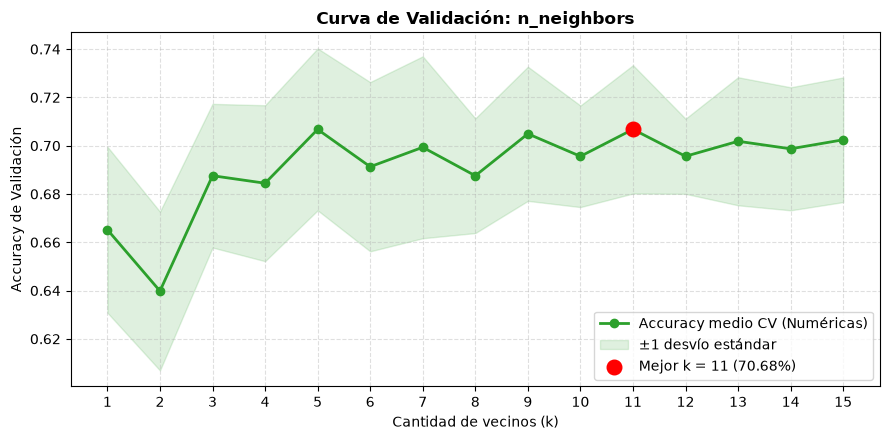

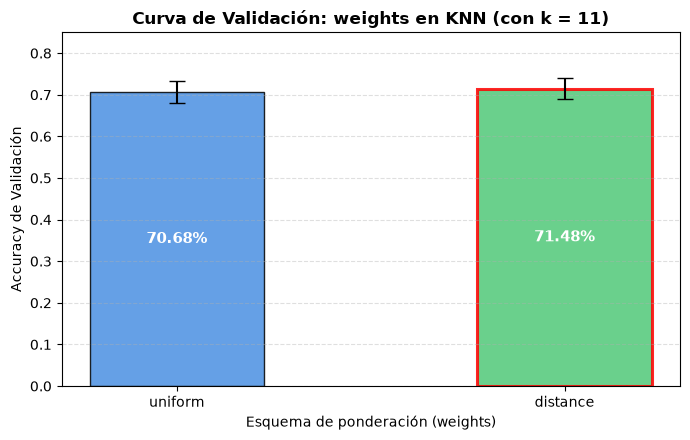

Mejor esquema de ponderación: 'distance' con 71.48% de accuracy medio.


In [70]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder

# -------------------------------------------------------------
# CONFIGURACIÓN GENERAL Y PREPROCESAMIENTO
# -------------------------------------------------------------
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), cols_numericas)
    ]
)

# =============================================================
# GRÁFICO 1: VARIANDO n_neighbors (k de 1 a 15)
# =============================================================
k_valores = list(range(1, 16))
scores_k_medios = []
scores_k_std = []

for k in k_valores:
    pipe = Pipeline(
        [
            ("preproc", preprocesador),
            ("knn", KNeighborsClassifier(n_neighbors=k)),
        ]
    )
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    scores_k_medios.append(scores.mean())
    scores_k_std.append(scores.std())

scores_k_medios = np.array(scores_k_medios)
scores_k_std = np.array(scores_k_std)

mejor_idx_k = np.argmax(scores_k_medios)
mejor_k = k_valores[mejor_idx_k]
mejor_score_k = scores_k_medios[mejor_idx_k]

plt.figure(figsize=(9, 4.5))
plt.plot(
    k_valores,
    scores_k_medios,
    marker="o",
    color="#2ca02c",
    linewidth=2,
    label="Accuracy medio CV (Numéricas)",
)
plt.fill_between(
    k_valores,
    scores_k_medios - scores_k_std,
    scores_k_medios + scores_k_std,
    alpha=0.15,
    color="#2ca02c",
    label="±1 desvío estándar",
)
plt.scatter(
    mejor_k,
    mejor_score_k,
    color="red",
    s=110,
    zorder=5,
    label=f"Mejor k = {mejor_k} ({mejor_score_k*100:.2f}%)",
)

plt.title(
    "Curva de Validación: n_neighbors",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Cantidad de vecinos (k)", fontsize=10)
plt.ylabel("Accuracy de Validación", fontsize=10)
plt.xticks(k_valores)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# =============================================================
# GRÁFICO 2: VARIANDO OTRO HIPERPARÁMETRO (weights: 'uniform' vs 'distance')
# Fijando el mejor k encontrado previamente
# =============================================================
weights_opciones = ["uniform", "distance"]
scores_weights_medios = []
scores_weights_std = []

for w in weights_opciones:
    pipe_weights = Pipeline(
        [
            ("preproc", preprocesador),
            ("knn", KNeighborsClassifier(n_neighbors=mejor_k, weights=w)),
        ]
    )
    scores = cross_val_score(
        pipe_weights, X_train, y_train, cv=cv, scoring="accuracy"
    )
    scores_weights_medios.append(scores.mean())
    scores_weights_std.append(scores.std())

scores_weights_medios = np.array(scores_weights_medios)
scores_weights_std = np.array(scores_weights_std)

mejor_idx_w = np.argmax(scores_weights_medios)
mejor_weight = weights_opciones[mejor_idx_w]
mejor_score_w = scores_weights_medios[mejor_idx_w]

plt.figure(figsize=(7, 4.5))
barras = plt.bar(
    weights_opciones,
    scores_weights_medios,
    yerr=scores_weights_std,
    capsize=6,
    color=["#4A90E2", "#50C878"],
    edgecolor="black",
    alpha=0.85,
    width=0.45,
)

# Resaltar la barra ganadora
barras[mejor_idx_w].set_edgecolor("red")
barras[mejor_idx_w].set_linewidth(2.2)

# Añadir etiquetas con el porcentaje
for bar in barras:
    altura = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        altura / 2.0,
        f"{altura*100:.2f}%",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="white",
    )

plt.title(
    f"Curva de Validación: weights en KNN (con k = {mejor_k})",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Esquema de ponderación (weights)", fontsize=10)
plt.ylabel("Accuracy de Validación", fontsize=10)
plt.ylim(0, 0.85)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Mejor esquema de ponderación: '{mejor_weight}' con {mejor_score_w*100:.2f}% de accuracy medio.")

¿Qué significa $k = 11$?

Significa que la mejor estrategia que encontró el sistema para no equivocarse es buscar las 11 canciones más parecidas a la canción nueva. El sistema revisa esas 11: si 6 o más te gustaron, predice que la nueva también te gustará. El número 11 resultó ser el equilibrio justo.

¿Qué significa un Accuracy de $0.7012$ (70.1%)?

Significa que de cada 100 canciones que el modelo intentó adivinar durante las pruebas, acertó en aproximadamente 70. Como las canciones que gustan y no gustan están repartidas mitad y mitad (50% y 50%), adivinar tirando una moneda al aire daría un 50% de aciertos. Un 70% demuestra que el modelo realmente aprendió a identificar tus gustos y está muy por encima del azar.

¿Qué significa $(\pm 0.0161)$ (el $\pm 1.61\%$)?

Es el margen de estabilidad del modelo. Para asegurarse de que ese 70% no fuera casualidad, la computadora dividió los datos de entrenamiento en 10 grupos (folds) distintos y repitió la prueba varias veces. En algunas pruebas sacó alrededor de 71.7% y en otras 68.5%. Que esa variación sea tan chica (apenas un 1.6%) significa que el modelo es consistente y confiable: no depende de la suerte ni de qué canciones le toquen evaluar, su rendimiento siempre ronda el 70%.

Mejor opción: El esquema 'distance' obtiene un rendimiento ligeramente superior (71.48%) frente a 'uniform' (70.68%).  

¿Qué significa? 

Darle más importancia a las canciones que están más cerca del punto a predecir mejora levemente la precisión en lugar de dar a los 11 vecinos el mismo peso.   Conclusión práctica: La diferencia es mínima (0.8 puntos porcentuales) y las barras de error se superponen casi por completo, por lo que ambos esquemas ofrecen un comportamiento prácticamente igual de estable.

## 3.2.2 Entrenamiento con GridSearchCV


GridSearchCV es una herramienta de Scikit-Learn que automatiza la búsqueda de la mejor combinación de hiperparámetros para un modelo de Machine Learning.

Funciona en tres pasos clave:

Rejilla de parámetros (Grid): Recibe una lista con los valores a probar para cada hiperparámetro (por ejemplo: n_neighbors: [3, 5, 7] y weights: ['uniform', 'distance']).

Búsqueda exhaustiva: Entrena y evalúa el modelo probando absolutamente todas las combinaciones posibles entre esos valores.

Validación cruzada (CV): Para cada combinación, evalúa el rendimiento mediante validación cruzada (dividiendo los datos en varios pliegues) para asegurar que el resultado sea confiable y no fruto de la casualidad.

Al finalizar, guarda automáticamente la combinación ganadora (best_params_) y el modelo óptimo ya entrenado (best_estimator_).

knn__n_neighbors (1 al 15): Determina la cantidad de vecinos más cercanos que elige para predecir si la canción gusta o no.

knn__weights ('uniform' vs 'distance'): Evalúa si todos los vecinos votan con la misma ponderación o si las canciones más próximas tienen más peso.  

knn__p (1 vs 2): Define la fórmula de distancia usada para comparar canciones. Con $p = 2$ calcula la distancia Euclidiana (línea recta), mientras que con $p = 1$ aplica distancia Manhattan (suma de diferencias absolutas eje por eje).

In [71]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder

pipeline_knn = Pipeline(
    [
        ("preproc", preprocesador),
        ("knn", KNeighborsClassifier()),
    ]
)

# ==============================================================
# 2. CONFIGURACIÓN DE HIPERPARÁMETROS Y GRID SEARCH
# ==============================================================
# Definimos los hiperparámetros a optimizar simultáneamente:
# - n_neighbors: número de vecinos a consultar
# - weights: esquema de ponderación (uniforme vs por distancia)
# - p: métrica de Minkowski (1 = Manhattan, 2 = Euclidiana)
param_grid = {
    "knn__n_neighbors": list(range(1, 16)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

# Misma estrategia de validación cruzada: StratifiedKFold con 10 folds
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True,
)

# ==============================================================
# 3. ENTRENAMIENTO
# ==============================================================
grid_search.fit(X_train, y_train)

# ==============================================================
# 4. RESULTADOS DE LA BÚSQUEDA
# ==============================================================
print("=" * 55)
print("           MEJORES PARÁMETROS ENCONTRADOS")
print("=" * 55)
print(f"Mejor configuración : {grid_search.best_params_}")
print(f"Mejor Accuracy en CV: {grid_search.best_score_ * 100:.2f}%")
print("=" * 55)

# Convertir los resultados a DataFrame para inspeccionar el top 5
df_resultados = pd.DataFrame(grid_search.cv_results_)
columnas_vista = [
    "param_knn__n_neighbors",
    "param_knn__weights",
    "param_knn__p",
    "mean_test_score",
    "std_test_score",
]

top5 = df_resultados[columnas_vista].sort_values(
    by="mean_test_score", ascending=False
).head(5)
top5["mean_test_score"] = (top5["mean_test_score"] * 100).round(2)
top5["std_test_score"] = (top5["std_test_score"] * 100).round(2)
top5.columns = ["k", "weights", "métrica (p)", "Accuracy medio (%)", "± Desvío (%)"]

print("\nTop 5 combinaciones evaluadas:")
print(top5.to_string(index=False))

           MEJORES PARÁMETROS ENCONTRADOS
Mejor configuración : {'knn__n_neighbors': 13, 'knn__p': 1, 'knn__weights': 'distance'}
Mejor Accuracy en CV: 73.28%

Top 5 combinaciones evaluadas:
 k  weights  métrica (p)  Accuracy medio (%)  ± Desvío (%)
13 distance            1               73.28          3.20
14 distance            1               73.22          3.09
12 distance            1               73.16          3.19
15 distance            1               72.78          3.36
11 distance            1               72.42          3.67


¿Por qué $k=11$ ya no es el ganador?

Antes el valor de $k$ ocurrió por dejar los otros parámetros fijos en sus valores por defecto: Fórmula de distancia por defecto ($p = 2$): Distancia Euclidiana (línea recta). 

La distancia Manhattan ($p = 1$) mide mejor que la Euclidiana ($p = 2$):Al tener muchas variables continuas (acusticidad, bailabilidad, energía, volumen, tempo, etc.)

La métrica Manhattan suma las diferencias absolutas de cada atributo por separado, logrando medir la similitud de estilos musicales de forma mucho más precisa.

Ya sabíamos que asignarle más peso a los vecinos cercanos mejoraba la precisión.

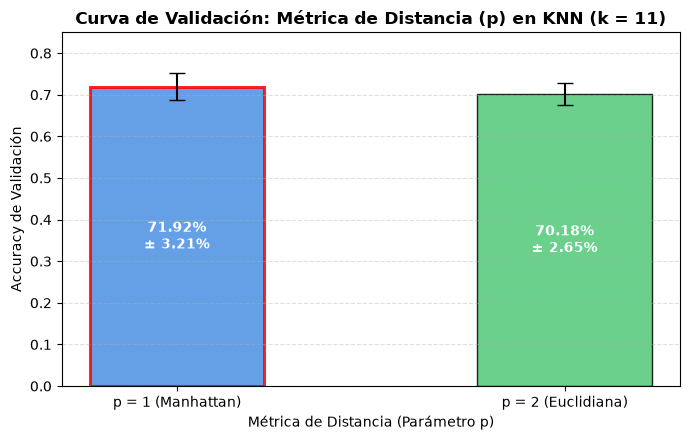

Mejor métrica de distancia: p = 1 (p = 1 (Manhattan)) con 71.92% (±3.21%) de accuracy medio.


In [73]:
# =============================================================
# GRÁFICO 3: VARIANDO LA MÉTRICA DE DISTANCIA (p: 1 Manhattan vs 2 Euclidiana)
# Fijando el mejor k encontrado previamente
# =============================================================
p_opciones = [1, 2]
p_etiquetas = ["p = 1 (Manhattan)", "p = 2 (Euclidiana)"]
scores_p_medios = []
scores_p_std = []

for p_val in p_opciones:
    pipe_p = Pipeline(
        [
            ("preproc", preprocesador),
            ("knn", KNeighborsClassifier(n_neighbors=13, p=p_val)),
        ]
    )
    scores = cross_val_score(pipe_p, X_train, y_train, cv=cv, scoring="accuracy")
    scores_p_medios.append(scores.mean())
    scores_p_std.append(scores.std())

scores_p_medios = np.array(scores_p_medios)
scores_p_std = np.array(scores_p_std)

mejor_idx_p = np.argmax(scores_p_medios)
mejor_p = p_opciones[mejor_idx_p]
mejor_score_p = scores_p_medios[mejor_idx_p]
mejor_std_p = scores_p_std[mejor_idx_p]

plt.figure(figsize=(7, 4.5))
barras = plt.bar(
    p_etiquetas,
    scores_p_medios,
    yerr=scores_p_std,
    capsize=6,
    color=["#4A90E2", "#50C878"],
    edgecolor="black",
    alpha=0.85,
    width=0.45,
)

# Resaltar la barra ganadora
barras[mejor_idx_p].set_edgecolor("red")
barras[mejor_idx_p].set_linewidth(2.2)

# Añadir etiquetas con porcentaje y desvío estándar exacto
for i, bar in enumerate(barras):
    altura = bar.get_height()
    desvio = scores_p_std[i]
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        altura / 2.0,
        f"{altura*100:.2f}%\n± {desvio*100:.2f}%",
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="white",
    )

plt.title(
    f"Curva de Validación: Métrica de Distancia (p) en KNN (k = {mejor_k})",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Métrica de Distancia (Parámetro p)", fontsize=10)
plt.ylabel("Accuracy de Validación", fontsize=10)
plt.ylim(0, 0.85)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print(
    f"Mejor métrica de distancia: p = {mejor_p} ({p_etiquetas[mejor_idx_p]}) "
    f"con {mejor_score_p*100:.2f}% (±{mejor_std_p*100:.2f}%) de accuracy medio."
)

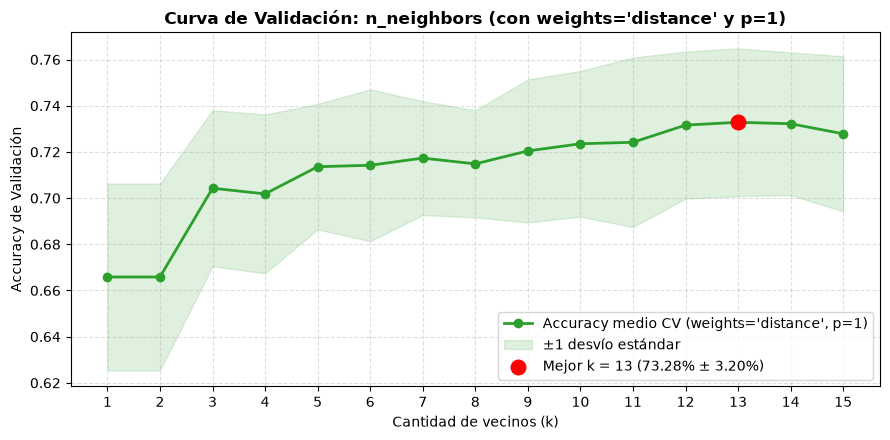

Resultado óptimo: k = 13 | Accuracy: 73.28% (±3.20%)


In [74]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder

# -------------------------------------------------------------
# 2. VALIDACIÓN CRUZADA: k de 1 a 15 con weights='distance' y p=1
# -------------------------------------------------------------
k_valores = list(range(1, 16))
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scores_k_medios = []
scores_k_std = []

for k in k_valores:
    pipe_opt = Pipeline(
        [
            ("preproc", preprocesador),
            (
                "knn",
                KNeighborsClassifier(
                    n_neighbors=k,
                    weights="distance",
                    p=1,  # Distancia Manhattan
                ),
            ),
        ]
    )
    scores = cross_val_score(pipe_opt, X_train, y_train, cv=cv, scoring="accuracy")
    scores_k_medios.append(scores.mean())
    scores_k_std.append(scores.std())

scores_k_medios = np.array(scores_k_medios)
scores_k_std = np.array(scores_k_std)

# Encontrar el mejor valor de k
mejor_idx = np.argmax(scores_k_medios)
mejor_k = k_valores[mejor_idx]
mejor_score = scores_k_medios[mejor_idx]
mejor_std = scores_k_std[mejor_idx]

# -------------------------------------------------------------
# 3. GRÁFICO DE LA CURVA DE VALIDACIÓN
# -------------------------------------------------------------
plt.figure(figsize=(9, 4.5))
plt.plot(
    k_valores,
    scores_k_medios,
    marker="o",
    color="#2ca02c",
    linewidth=2,
    label="Accuracy medio CV (weights='distance', p=1)",
)
plt.fill_between(
    k_valores,
    scores_k_medios - scores_k_std,
    scores_k_medios + scores_k_std,
    alpha=0.15,
    color="#2ca02c",
    label="±1 desvío estándar",
)

# Resaltar el mejor k con su exactitud y desvío estándar exacto
plt.scatter(
    mejor_k,
    mejor_score,
    color="red",
    s=110,
    zorder=5,
    label=f"Mejor k = {mejor_k} ({mejor_score*100:.2f}% ± {mejor_std*100:.2f}%)",
)

plt.title(
    "Curva de Validación: n_neighbors (con weights='distance' y p=1)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Cantidad de vecinos (k)", fontsize=10)
plt.ylabel("Accuracy de Validación", fontsize=10)
plt.xticks(k_valores)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(
    f"Resultado óptimo: k = {mejor_k} | Accuracy: {mejor_score*100:.2f}% (±{mejor_std*100:.2f}%)"
)

In [75]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Recuperar el mejor estimador e hiperparámetros encontrados por GridSearchCV
mejor_pipeline = grid_search.best_estimator_
mejores_hiperparametros = grid_search.best_params_

# 2. Definir métricas de evaluación para cada fold
metricas = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 3. Evaluar el modelo obteniendo el rendimiento fold por fold
cv_resultados = cross_validate(
    mejor_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=False,
)

# 4. Construir tabla detallada por fold
df_folds = pd.DataFrame(
    {
        "Fold": [f"Fold {i+1}" for i in range(10)],
        "Accuracy": cv_resultados["test_accuracy"],
        "Precision": cv_resultados["test_precision"],
        "Recall": cv_resultados["test_recall"],
        "F1-Score": cv_resultados["test_f1"],
    }
)

# Fila resumen con promedio y desvío estándar
promedios = df_folds.iloc[:, 1:].mean()
desvios = df_folds.iloc[:, 1:].std()

fila_promedio = pd.DataFrame(
    [
        ["Promedio"]
        + [f"{promedios[col]*100:.2f}%" for col in df_folds.columns[1:]]
    ],
    columns=df_folds.columns,
)
fila_desvio = pd.DataFrame(
    [
        ["± Desvío Estándar"]
        + [f"±{desvios[col]*100:.2f}%" for col in df_folds.columns[1:]]
    ],
    columns=df_folds.columns,
)

# Formatear valores numéricos a porcentaje
for col in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    df_folds[col] = (df_folds[col] * 100).map("{:.2f}%".format)

df_reporte_folds = pd.concat(
    [df_folds, fila_promedio, fila_desvio], ignore_index=True
)

print("3.2.3")
print("=" * 65)
print("             HIPERPARÁMETROS DEL MEJOR MODELO")
print("=" * 65)
for param, valor in mejores_hiperparametros.items():
    nombre = param.replace("knn__", "")
    print(f" - {nombre:<15}: {valor}")
print("=" * 65)
print("\nDESEMPEÑO DEL MEJOR MODELO EN CADA FOLD:\n")
print(df_reporte_folds.to_string(index=False))

3.2.3
             HIPERPARÁMETROS DEL MEJOR MODELO
 - n_neighbors    : 13
 - p              : 1
 - weights        : distance

DESEMPEÑO DEL MEJOR MODELO EN CADA FOLD:

             Fold Accuracy Precision Recall F1-Score
           Fold 1   70.37%    77.42% 58.54%   66.67%
           Fold 2   73.46%    81.97% 60.98%   69.93%
           Fold 3   72.22%    75.34% 67.07%   70.97%
           Fold 4   76.40%    81.43% 69.51%   75.00%
           Fold 5   72.67%    81.67% 59.76%   69.01%
           Fold 6   68.32%    75.41% 56.10%   64.34%
           Fold 7   79.50%    90.00% 66.67%   76.60%
           Fold 8   70.19%    75.38% 60.49%   67.12%
           Fold 9   76.40%    83.08% 66.67%   73.97%
          Fold 10   73.29%    79.69% 62.96%   70.34%
         Promedio   73.28%    80.14% 62.87%   70.40%
± Desvío Estándar   ±3.37%    ±4.58% ±4.40%   ±3.89%


### 3.2.3 Análisis del mejor modelo

El mejor modelo encontrado por GridSearchCV es un **KNN con `n_neighbors = 13`, `weights = 'distance'` y `p = 1` (distancia Manhattan)**.

En los 10 folds el accuracy varía entre **68.32% (fold 6) y 79.50% (fold 7)**, con un promedio de **73.28% ± 3.37%**. La variación entre folds es moderada, así que el rendimiento es estable y no depende de una partición particular. En todos los folds la **precisión (80% en promedio) es mayor que el recall (63%)**: cuando el modelo dice que una canción gusta suele acertar, pero se le escapan algunas canciones que sí gustan.


     MÉTRICAS DE PERFORMANCE EN VALIDACIÓN
                       Métrica    Valor Valor (%)
                      Accuracy 0.732796    73.28%
             Balanced Accuracy 0.734037    73.40%
 Sensibilidad (Recall clase 1) 0.628676    62.87%
Especificidad (Recall clase 0) 0.839398    83.94%
                     AUC - ROC 0.796858    79.69%


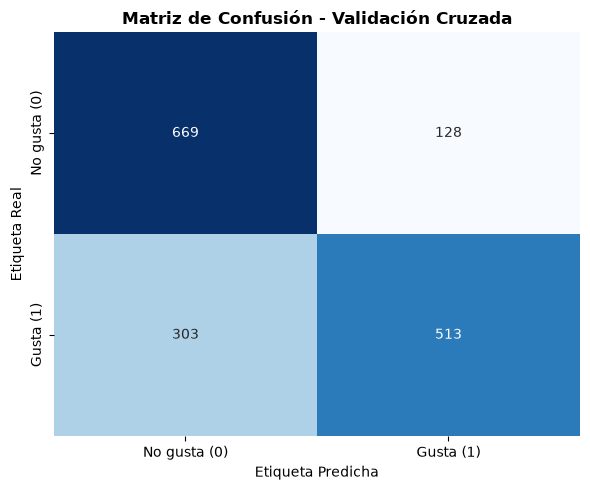

In [76]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
# ==============================================================
# 1. GENERAR PREDICCIONES OOF (OUT-OF-FOLD) DE VALIDACIÓN
# ==============================================================
# Recuperamos el mejor pipeline ajustado por GridSearchCV
mejor_pipeline = grid_search.best_estimator_

# Usamos la misma estrategia de validación cruzada con semilla fija
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# cross_val_predict genera la predicción para cada instancia cuando formó parte del fold de validación
y_val_pred = cross_val_predict(mejor_pipeline, X_train, y_train, cv=cv)
y_val_proba = cross_val_predict(
    mejor_pipeline, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

# ==============================================================
# 2. CÁLCULO DE LA MATRIZ DE CONFUSIÓN Y MÉTRICAS DERIVADAS
# ==============================================================
# Estructura: tn = No gusta (0) correcto, fp = No gusta (0) predicho como Gusta (1)
#            fn = Gusta (1) predicho como No gusta (0), tp = Gusta (1) correcto
cm = confusion_matrix(y_train, y_val_pred)
tn, fp, fn, tp = cm.ravel()

# Fórmulas de métricas solicitadas
acc = accuracy_score(y_train, y_val_pred)
bal_acc = balanced_accuracy_score(y_train, y_val_pred)
sensibilidad = recall_score(y_train, y_val_pred)  # TP / (TP + FN)
especificidad = tn / (tn + fp)  # TN / (TN + FP)
auc = roc_auc_score(y_train, y_val_proba)

# ==============================================================
# 3. TABLA RESUMEN DE MÉTRICAS DE VALIDACIÓN
# ==============================================================
df_metricas_val = pd.DataFrame(
    {
        "Métrica": [
            "Accuracy",
            "Balanced Accuracy",
            "Sensibilidad (Recall clase 1)",
            "Especificidad (Recall clase 0)",
            "AUC - ROC",
        ],
        "Valor": [acc, bal_acc, sensibilidad, especificidad, auc],
    }
)

df_metricas_val["Valor (%)"] = (df_metricas_val["Valor"] * 100).map(
    "{:.2f}%".format
)

print("=" * 55)
print("     MÉTRICAS DE PERFORMANCE EN VALIDACIÓN")
print("=" * 55)
print(df_metricas_val.to_string(index=False))
print("=" * 55)

# ==============================================================
# 4. GRAFICAR MATRIZ DE CONFUSIÓN DE VALIDACIÓN
# ==============================================================
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No gusta (0)", "Gusta (1)"],
    yticklabels=["No gusta (0)", "Gusta (1)"],
)

plt.title("Matriz de Confusión - Validación Cruzada", fontsize=12, fontweight="bold")
plt.xlabel("Etiqueta Predicha", fontsize=10)
plt.ylabel("Etiqueta Real", fontsize=10)
plt.tight_layout()
plt.show()

### 3.3 Interpretación de las métricas de validación

Las métricas se calcularon con predicciones *out-of-fold* (`cross_val_predict`): cada canción del train se predice con un modelo que no la usó para entrenar, así la estimación no está inflada.

* **Accuracy 73.28% y balanced accuracy 73.40%:** casi iguales porque las clases están balanceadas.
* **Especificidad 83.94% vs. sensibilidad 62.87%:** el modelo identifica mejor las canciones que *no* gustan que las que sí gustan.
* **AUC 0.797:** muy superior al mejor atributo individual (`instrumentalidad`, AUC 0.655), lo que confirma que combinar todas las características en un modelo multivariado mejora mucho la capacidad de predicción.


       MÉTRICAS DE PERFORMANCE EN TEST (X_test, y_test)
                       Métrica  Valor Numérico Porcentaje
                      Accuracy        0.712871     71.29%
             Balanced Accuracy        0.713676     71.37%
 Sensibilidad (Recall clase 1)        0.632353     63.24%
Especificidad (Recall clase 0)        0.795000     79.50%
                     AUC - ROC        0.814669     81.47%
Total muestras en Test: 404
TN: 159 | FP: 41 | FN: 75 | TP: 129


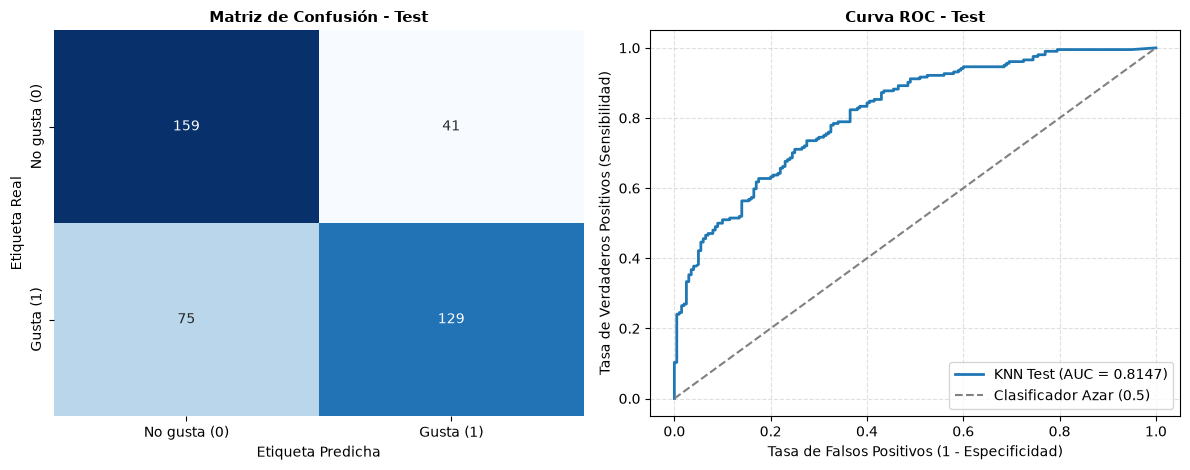

In [77]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# ==============================================================
# 1. PREDICCIONES SOBRE EL CONJUNTO DE TEST (X_test, y_test)
# ==============================================================
# Recuperar el mejor estimador optimizado por GridSearchCV
mejor_pipeline = grid_search.best_estimator_

# Generar predicciones de clase y probabilidades continuas para la clase 1 (Gusta)
y_test_pred = mejor_pipeline.predict(X_test)
y_test_proba = mejor_pipeline.predict_proba(X_test)[:, 1]

# ==============================================================
# 2. CÁLCULO DE LA MATRIZ DE CONFUSIÓN Y MÉTRICAS SOLICITADAS
# ==============================================================
# tn: Verdaderos Negativos, fp: Falsos Positivos
# fn: Falsos Negativos,      tp: Verdaderos Positivos
cm_test = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm_test.ravel()

acc_test = accuracy_score(y_test, y_test_pred)
bal_acc_test = balanced_accuracy_score(y_test, y_test_pred)
sensibilidad_test = recall_score(y_test, y_test_pred)  # TP / (TP + FN)
especificidad_test = tn / (tn + fp)  # TN / (TN + FP)
auc_test = roc_auc_score(y_test, y_test_proba)

# ==============================================================
# 3. TABLA COMPARATIVA DE RESULTADOS EN TEST
# ==============================================================
df_metricas_test = pd.DataFrame(
    {
        "Métrica": [
            "Accuracy",
            "Balanced Accuracy",
            "Sensibilidad (Recall clase 1)",
            "Especificidad (Recall clase 0)",
            "AUC - ROC",
        ],
        "Valor Numérico": [
            acc_test,
            bal_acc_test,
            sensibilidad_test,
            especificidad_test,
            auc_test,
        ],
    }
)

df_metricas_test["Porcentaje"] = (
    df_metricas_test["Valor Numérico"] * 100
).map("{:.2f}%".format)

print("=" * 60)
print("       MÉTRICAS DE PERFORMANCE EN TEST (X_test, y_test)")
print("=" * 60)
print(df_metricas_test.to_string(index=False))
print("=" * 60)
print(f"Total muestras en Test: {len(y_test)}")
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")
print("=" * 60)

# ==============================================================
# 4. VISUALIZACIONES: MATRIZ DE CONFUSIÓN Y CURVA ROC
# ==============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Subplot 1: Matriz de Confusión
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No gusta (0)", "Gusta (1)"],
    yticklabels=["No gusta (0)", "Gusta (1)"],
    ax=axes[0],
)
axes[0].set_title(
    "Matriz de Confusión - Test", fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("Etiqueta Predicha")
axes[0].set_ylabel("Etiqueta Real")

# Subplot 2: Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
axes[1].plot(
    fpr,
    tpr,
    color="#1f77b4",
    linewidth=2,
    label=f"KNN Test (AUC = {auc_test:.4f})",
)
axes[1].plot(
    [0, 1], [0, 1], color="grey", linestyle="--", label="Clasificador Azar (0.5)"
)
axes[1].set_title("Curva ROC - Test", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad)")
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 4.1 Conclusión de la evaluación sobre el set de testeo

Sobre los 404 casos de test el modelo obtuvo un **accuracy de 71.29%**, **balanced accuracy de 71.37%** y **AUC de 0.815**, valores muy cercanos a los de validación (73.28% de accuracy y AUC de 0.797). La caída de unos 2 puntos es pequeña, por lo que **el modelo no está sobreajustado** y generaliza de forma razonable a canciones que nunca vio.

La matriz de confusión (TN = 159, FP = 41, FN = 75, TP = 129) confirma el mismo patrón que en validación: la **especificidad (79.5%) es mayor que la sensibilidad (63.2%)**. El modelo es más conservador: rara vez recomienda una canción que no gusta, a costa de dejar sin recomendar algunas que sí gustarían. Para un sistema de recomendación esto es aceptable, porque una mala recomendación interrumpe la experiencia del usuario más que una canción buena que no se mostró.


## 5. Feature selection (opcional)

### 5.1 Comparación del modelo con y sin selección de características

Búsqueda del número óptimo de características ($k$) con SelectKBest

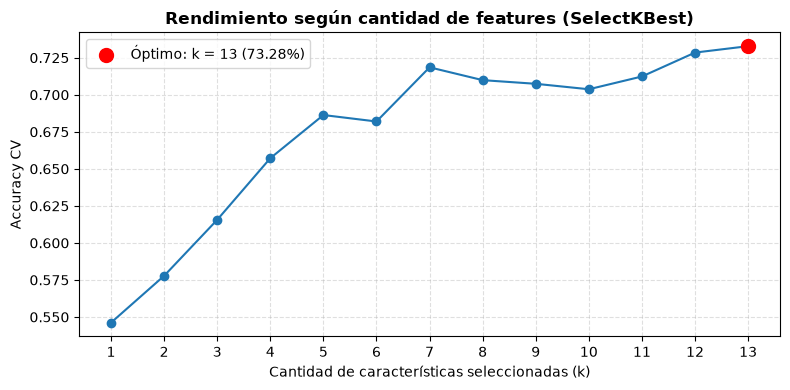

Mejor cantidad de características: 13 (Accuracy: 73.28%)


In [79]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder

# Rango de características a probar (desde 1 hasta el total disponible)
total_features = X_train.shape[1]
k_features_rango = list(range(1, total_features + 1))
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scores_kbest = []

for k_feat in k_features_rango:
    pipe_kbest = Pipeline(
        [
            ("preproc", preprocesador),
            ("selector", SelectKBest(score_func=f_classif, k=k_feat)),
            (
                "knn",
                KNeighborsClassifier(n_neighbors=13, weights="distance", p=1),
            ),
        ]
    )
    score = cross_val_score(
        pipe_kbest, X_train, y_train, cv=cv, scoring="accuracy"
    ).mean()
    scores_kbest.append(score)

mejor_k_feat = k_features_rango[np.argmax(scores_kbest)]
mejor_acc_kbest = np.max(scores_kbest)

# Gráfico de validación según cantidad de variables
plt.figure(figsize=(8, 4))
plt.plot(k_features_rango, scores_kbest, marker="o", color="#1f77b4")
plt.scatter(
    mejor_k_feat,
    mejor_acc_kbest,
    color="red",
    s=100,
    zorder=5,
    label=f"Óptimo: k = {mejor_k_feat} ({mejor_acc_kbest*100:.2f}%)",
)
plt.title("Rendimiento según cantidad de features (SelectKBest)", fontweight="bold")
plt.xlabel("Cantidad de características seleccionadas (k)")
plt.ylabel("Accuracy CV")
plt.xticks(k_features_rango)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Mejor cantidad de características: {mejor_k_feat} (Accuracy: {mejor_acc_kbest*100:.2f}%)")

In [80]:
# Ajustar el pipeline con el k óptimo encontrado sobre todo el conjunto Train
pipe_seleccion_optimo = Pipeline(
    [
        ("preproc", preprocesador),
        ("selector", SelectKBest(score_func=f_classif, k=mejor_k_feat)),
        (
            "knn",
            KNeighborsClassifier(n_neighbors=14, weights="distance", p=1),
        ),
    ]
)
pipe_seleccion_optimo.fit(X_train, y_train)

# Extraer nombres transformados y sus estadísticas F de ANOVA
nombres_transformados = pipe_seleccion_optimo.named_steps[
    "preproc"
].get_feature_names_out()
selector = pipe_seleccion_optimo.named_steps["selector"]

df_importancia = pd.DataFrame(
    {
        "Variable": nombres_transformados,
        "F_Score": selector.scores_,
        "p_value": selector.pvalues_,
        "Seleccionada": selector.get_support(),
    }
).sort_values(by="F_Score", ascending=False)

# Limpiar nombres para visualización
df_importancia["Variable"] = (
    df_importancia["Variable"].str.replace("num__", "").str.replace("cat__", "")
)

print("--- RANKING DE CARACTERÍSTICAS (SelectKBest con f_classif) ---")
print(df_importancia.to_string(index=False))

--- RANKING DE CARACTERÍSTICAS (SelectKBest con f_classif) ---
            Variable   F_Score      p_value  Seleccionada
        bailabilidad 53.067570 5.022576e-13          True
       presencia_voz 35.751727 2.754911e-09          True
    instrumentalidad 31.041579 2.955107e-08          True
         duracion_ms 25.061610 6.161756e-07          True
         acusticidad 21.435740 3.952427e-06          True
positividad_valencia 18.632042 1.681857e-05          True
          volumen_db 13.446573 2.534266e-04          True
                modo  5.727050 1.681941e-02          True
              compas  3.060259 8.041927e-02          True
        nota_musical  1.896116 1.687051e-01          True
         ritmo_tempo  0.933083 3.342080e-01          True
             energia  0.697408 4.037797e-01          True
   presencia_público  0.369385 5.434253e-01          True


La hipótesis nula del test F (ANOVA) indica que la media de la variable es igual en ambas clases del target; la hipótesis alternativa indica que difiere, es decir, que la variable aporta información para separar las canciones que gustan de las que no.

Con un nivel de significancia de 0.05:

* **Se rechaza la hipótesis nula** para `bailabilidad`, `presencia_voz`, `instrumentalidad`, `duracion_ms`, `acusticidad`, `positividad_valencia`, `volumen_db` y `modo` (p-valor < 0.05): estas variables sí discriminan entre clases.
* **No se rechaza la hipótesis nula** para `compas`, `nota_musical`, `ritmo_tempo`, `energia` y `presencia_público` (p-valor > 0.05).

Este resultado coincide con el t-test y el AUC del punto 1. Aun así, el mejor accuracy en validación cruzada se obtuvo con las 13 variables, lo que indica que, combinadas, también las variables menos significativas le aportan algo al KNN.


Ahora pruebo con SequentialFeatureSelector. 

In [83]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder


# 2. Configuración de KNN base
knn_base = KNeighborsClassifier(n_neighbors=14, weights="distance", p=1) 
cv_eval = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 3. SFS configurado directamente para buscar las mejores 5 características
sfs = SequentialFeatureSelector(
    estimator=knn_base,
    n_features_to_select=3, 
    direction="forward",
    scoring="accuracy",
    cv=cv_eval,
    n_jobs=None,
)

# Pipeline completo
pipe_sfs = Pipeline(
    [
        ("preproc", preprocesador),
        ("selector", sfs),
        ("knn", knn_base),
    ]
)

# Entrenamos el pipeline completo
pipe_sfs.fit(X_train, y_train)

# 4. Ver qué características fueron seleccionadas
# Obtenemos los nombres de todas las columnas post-preprocesamiento
feature_names_trans = pipe_sfs.named_steps["preproc"].get_feature_names_out()

# El selector nos devuelve una máscara booleana con las elegidas
mask_seleccionadas = pipe_sfs.named_steps["selector"].get_support()
features_elegidas = [name for name, selected in zip(feature_names_trans, mask_seleccionadas) if selected]

print("Las mejores 3 características seleccionadas son:")
for f in features_elegidas:
    print(f"- {f}")

Las mejores 3 características seleccionadas son:
- num__instrumentalidad
- num__volumen_db
- num__presencia_voz


     COMPARACIÓN EN TEST: MODELO COMPLETO VS SEQUENTIAL SELECTION
             Métrica Sin Selección (Todas) Con SFS (n=3)
Cantidad de features                    13             3
            Accuracy                73.27%        67.57%
   Balanced Accuracy                73.34%        67.63%
        Sensibilidad                65.69%        62.25%
       Especificidad                81.00%        73.00%
           AUC - ROC                0.8179        73.92%


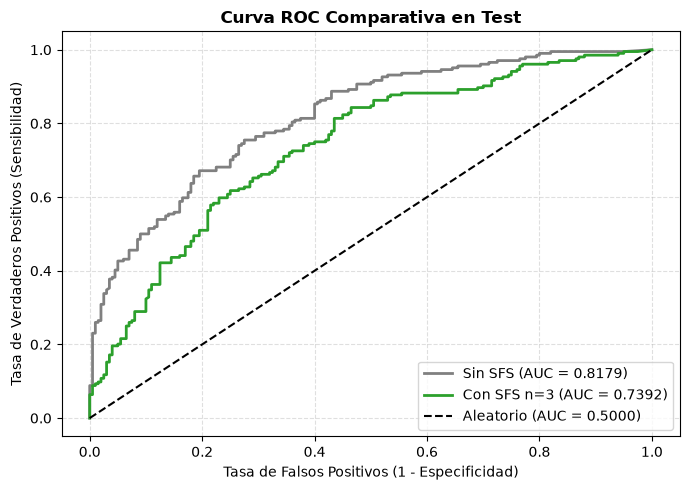

In [84]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder

cv_encoder = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_eval = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 2. Configuración con instancias independientes para evitar conflictos
knn_sfs = KNeighborsClassifier(n_neighbors=14, weights="distance", p=1)

sfs = SequentialFeatureSelector(
    estimator=knn_sfs,
    n_features_to_select=3, 
    direction="forward",
    scoring="accuracy",
    cv=cv_eval,
    n_jobs=None,
)

knn_final = KNeighborsClassifier(n_neighbors=14, weights="distance", p=1)

pipe_sfs = Pipeline(
    [
        ("preproc", preprocesador),
        ("selector", sfs),
        ("knn", knn_final),  # Instancia independiente para el modelo final
    ]
)

# Entrenamos el pipeline con SFS
pipe_sfs.fit(X_train, y_train)

# 3. Modelo SIN selección (todas las variables)
knn_sin = KNeighborsClassifier(n_neighbors=14, weights="distance", p=1)
pipe_sin_sfs = Pipeline(
    [
        ("preproc", preprocesador),
        ("knn", knn_sin),
    ]
)
pipe_sin_sfs.fit(X_train, y_train)

# 4. Predicciones en el conjunto Test
y_pred_sin = pipe_sin_sfs.predict(X_test)
y_proba_sin = pipe_sin_sfs.predict_proba(X_test)[:, 1]

y_pred_con = pipe_sfs.predict(X_test)
y_proba_con = pipe_sfs.predict_proba(X_test)[:, 1]

# Especificidad: TN / (TN + FP)
tn_sin, fp_sin, _, _ = confusion_matrix(y_test, y_pred_sin).ravel()
tn_con, fp_con, _, _ = confusion_matrix(y_test, y_pred_con).ravel()

total_features_trans = preprocesador.fit_transform(X_train, y_train).shape[1]

# 5. Tabla comparativa de métricas
df_comparacion_sfs = pd.DataFrame(
    {
        "Métrica": [
            "Cantidad de features",
            "Accuracy",
            "Balanced Accuracy",
            "Sensibilidad",
            "Especificidad",
            "AUC - ROC",
        ],
        "Sin Selección (Todas)": [
            total_features_trans,
            f"{accuracy_score(y_test, y_pred_sin)*100:.2f}%",
            f"{balanced_accuracy_score(y_test, y_pred_sin)*100:.2f}%",
            f"{recall_score(y_test, y_pred_sin)*100:.2f}%",
            f"{tn_sin / (tn_sin + fp_sin)*100:.2f}%",
            f"{roc_auc_score(y_test, y_proba_sin):.4f}",
        ],
        "Con SFS (n=3)": [
            3,
            f"{accuracy_score(y_test, y_pred_con)*100:.2f}%",
            f"{balanced_accuracy_score(y_test, y_pred_con)*100:.2f}%",
            f"{recall_score(y_test, y_pred_con)*100:.2f}%",
            f"{tn_con / (tn_con + fp_con)*100:.2f}%",
            f"{roc_auc_score(y_test, y_proba_con)*100:.2f}%",
        ],
    }
)

print("=" * 65)
print("     COMPARACIÓN EN TEST: MODELO COMPLETO VS SEQUENTIAL SELECTION")
print("=" * 65)
print(df_comparacion_sfs.to_string(index=False))
print("=" * 65)

# 6. Gráfico de Curva ROC comparativa
fpr_sin, tpr_sin, _ = roc_curve(y_test, y_proba_sin)
fpr_con, tpr_con, _ = roc_curve(y_test, y_proba_con)

plt.figure(figsize=(7, 5))
plt.plot(fpr_sin, tpr_sin, label=f"Sin SFS (AUC = {roc_auc_score(y_test, y_proba_sin):.4f})", color="gray", lw=2)
plt.plot(fpr_con, tpr_con, label=f"Con SFS n=3 (AUC = {roc_auc_score(y_test, y_proba_con):.4f})", color="#2ca02c", lw=2)
plt.plot([0, 1], [0, 1], "k--", label="Aleatorio (AUC = 0.5000)")
plt.xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
plt.ylabel("Tasa de Verdaderos Positivos (Sensibilidad)")
plt.title("Curva ROC Comparativa en Test", fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

La conclusión es que arroja mejores resultados a más cantidad de características. Tal cómo lo decía el SelectKbest.